In [1]:
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
import matplotlib.pyplot as     plt
from sunsim import *

from scipy import optimize


In [2]:
### PATHS

path_data_in  = '/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/.shortcut-targets-by-id/1WjPH0zd5VocfpASpJ6hkrfTrENlZi8jh/Sun Mask/Data/Input/'
path_data_out = '/Users/sophiestucki/Documents/poet/output/'
path_figs     = '/Users/sophiestucki/Documents/poet/output/'


# Read VALD linelist
df_vald = pd.read_csv(path_data_out+'SUN_LINELIST_VALD.csv')
Nline_vald = len(df_vald)
wave_vald = df_vald['wave'].values
depth_vald = df_vald['depth_vald'].values

# Read PoET spectrum
df_p = pd.read_csv(path_data_out+'SUN_SPECTRUM_POET.csv')
wave_p = df_p['wave'].values
flux_p = df_p['flux'].values

# Read MURaM spectrum
df = pd.read_csv(path_data_out+'SUN_SPECTRUM_MURAM.csv')
wave = df['wave'].values
flux = df['flux'].values

In [ ]:
def find_spectral_lines(wave, flux, df_vald, tolerance=0.1, prominence=0.01, distance_weight=0.5, depth_weight=0.5):
    minima, _ = find_peaks(-flux, prominence=prominence)

    lines = []

    vald_waves = df_vald['wave'].values
    vald_depths = df_vald['depth_vald'].values

    for i in minima:

        # First maximum to the left of the minimum
        i_left = i-1
        while i_left > 0 and flux[i_left-1] > flux[i_left]:
            i_left -= 1

        # First maximum to the right of the minimum
        i_right = i+1
        while i_right < len(flux)-1 and flux[i_right+1] > flux[i_right]:
            i_right += 1

        if i_left == 0 or i_right == len(flux)-1:
            continue

        w_min = wave[i]
        w_left = wave[i_left]
        w_right = wave[i_right]

        f_min = flux[i]
        f_left = flux[i_left]
        f_right = flux[i_right]

        depth_left = f_left-f_min
        depth_right = f_right-f_min
        depth = 0.5*(depth_left+depth_right)

        # All VALD lines between the two local maxima
        candidate_mask = (vald_waves > w_left) & (vald_waves < w_right) & (np.abs(w_min-vald_waves) < tolerance)
        candidate_pos = np.where(candidate_mask)[0]

        if len(candidate_pos) > 0:

            candidate_waves = vald_waves[candidate_pos]
            candidate_depths = vald_depths[candidate_pos]

            # Difference in wavelength and depth
            delta_wave = np.abs(candidate_waves-w_min)
            delta_depth = np.abs(candidate_depths-depth)

            line_width = w_right-w_left


            # Dimensionless physical differences
            distance_metric = delta_wave/line_width #sigma better, or fwhm? 
            # RV shift between the minima and all vald lines, and then normalized the distance metric and divide by the median or divide by 350 m/S since its the sun
            # histogram of all the RV shift of the lines compared to all vald line => distance metric rv shift / sigma of the hist
            depth_metric = delta_depth/np.maximum(depth,1e-12) 


            # Combined matching score: smaller = better
            score = distance_weight*distance_metric + depth_weight*depth_metric

            best = np.argmin(score)
            j_vald = candidate_pos[best]

            vald_wave = vald_waves[j_vald]
            vald_depth = vald_depths[j_vald]
            vald_index = df_vald.index[j_vald]
            delta_vald = w_min-vald_wave
            vald_score = score[best]
            n_vald_candidates = len(candidate_pos)

        else:
            vald_wave = np.nan
            vald_depth = np.nan
            vald_index = np.nan
            delta_vald = np.nan
            vald_score = np.nan
            n_vald_candidates = 0

        lines.append({'wave_min': w_min, 'flux_min': f_min, 'i_left': i_left, 'wave_left_max': w_left, 'flux_left_max': f_left, 'i_right': i_right, 'wave_right_max': w_right, 'flux_right_max': f_right, 'depth': depth, 'vald_index': vald_index, 'vald_wave': vald_wave, 'vald_depth': vald_depth, 'delta_vald': delta_vald, 'vald_score': vald_score, 'n_vald_candidates': n_vald_candidates, 'candidates': candidate_pos})

    return pd.DataFrame(lines)

In [4]:
tolerance = 0.05
prominence = 0.01

lines_p = find_spectral_lines(wave_p, flux_p, df_vald, tolerance=tolerance, prominence=0.01, distance_weight=0.5, depth_weight=0.5)
lines = find_spectral_lines(wave, flux, df_vald,  tolerance=tolerance, prominence=0.01, distance_weight=0.5, depth_weight=0.5)

lines_p_raw = lines_p.copy()
lines_raw = lines.copy()

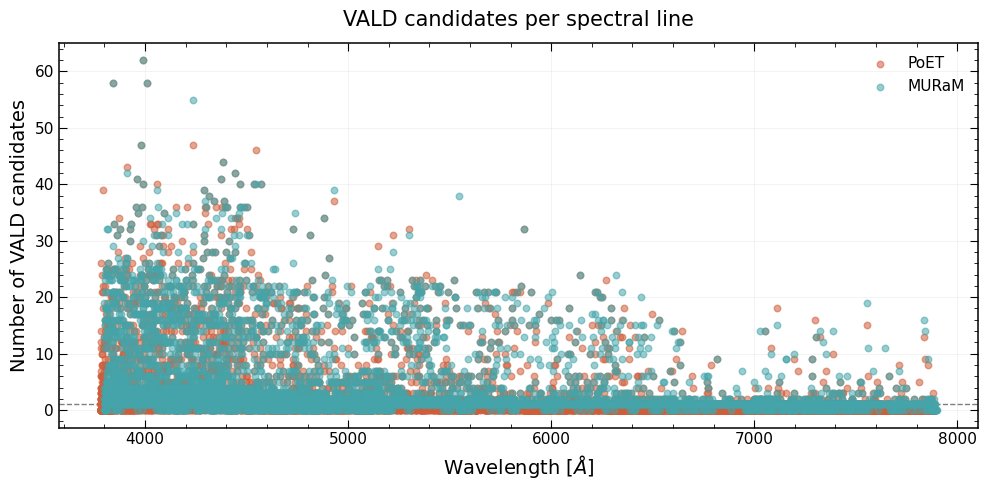

In [ ]:
fig, ax = plt.subplots(figsize=(10,5))

ax.scatter(lines_p['wave_min'],lines_p['n_vald_candidates'],s=22,alpha=0.55,label='PoET',color="#cf5d3a",zorder=3)
ax.scatter(lines['wave_min'],lines['n_vald_candidates'],s=22,alpha=0.55,label='MURaM',color="#45a5aa",zorder=3)

ax.axhline(1,color='k',ls='--',lw=1,alpha=0.5)

ax.set_xlabel(r'Wavelength [$\AA$]',fontsize=14)
ax.set_ylabel('Number of VALD candidates',fontsize=14)
ax.set_title('VALD candidates per spectral line',fontsize=15,pad=12)

ax.legend(frameon=False,fontsize=11)

ax.tick_params(axis='both',which='major',labelsize=11,direction='in',top=True,right=True,length=6)
ax.tick_params(axis='both',which='minor',direction='in',top=True,right=True,length=3)
ax.minorticks_on()

ax.grid(alpha=0.15,linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

#TODO histogram of nbr of candidate

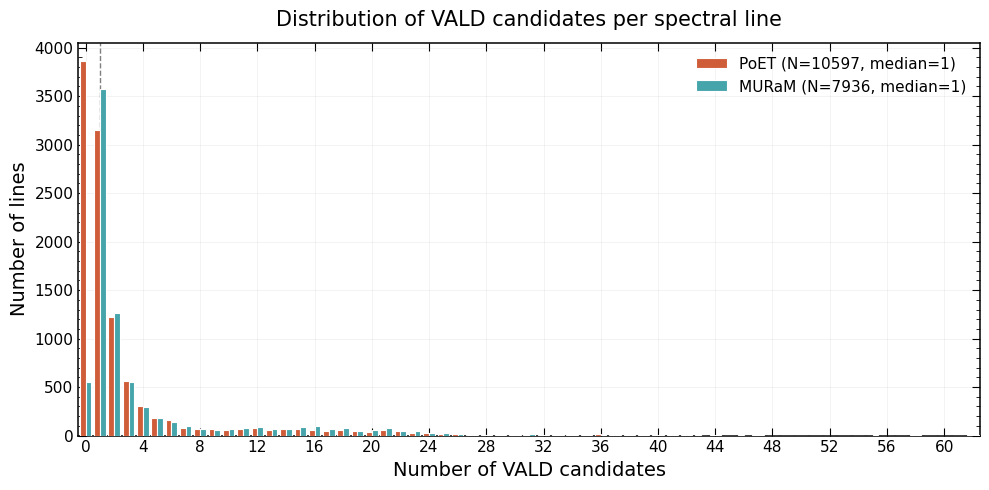

In [7]:
# All the lines detected in PoET and in MURaM (lines_p_raw, lines_raw: before any selection, so the figure does not
# depend on the cells run before)
# One bin per integer count, centred on the integer
n_max = int(max(lines_p_raw['n_vald_candidates'].max(), lines_raw['n_vald_candidates'].max()))
bins = np.arange(-0.5, n_max + 1.5, 1)

centres = np.arange(0, n_max + 1)
width = 0.4  # each bar takes 0.4 of the unit bin, leaving a small gap between groups

fig, ax = plt.subplots(figsize=(10,5))

for k, (df, label, color) in enumerate([(lines_p_raw, 'PoET', "#cf5d3a"), (lines_raw, 'MURaM', "#45a5aa")]):
    n = df['n_vald_candidates']
    counts, _ = np.histogram(n, bins=bins)
    offset = (k - 0.5) * width  # PoET left of the integer, MURaM right
    ax.bar(centres + offset, counts, width=width, color=color, edgecolor='white', linewidth=0.8, zorder=3,
           label=f'{label} (N={len(n)}, median={np.median(n):.0f})')

ax.axvline(1, color='k', ls='--', lw=1, alpha=0.5)

ax.set_xlabel('Number of VALD candidates', fontsize=14)
ax.set_ylabel('Number of lines', fontsize=14)
ax.set_title('Distribution of VALD candidates per spectral line', fontsize=15, pad=12)
ax.set_xlim(bins[0], bins[-1])
# ax.set_yscale('log')  # uncomment if the tail is hard to see

ax.legend(frameon=False, fontsize=11)

ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks(centres if n_max <= 30 else centres[::max(1, n_max // 15)])

ax.grid(alpha=0.15, linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

In [6]:
dup_p = (lines_p['vald_index'].value_counts() > 1)
dup_m = (lines['vald_index'].value_counts() > 1)

dup_idx_p = dup_p[dup_p].index
dup_idx_m = dup_m[dup_m].index

print('PoET duplicated VALD wavelengths:')
print(lines_p.loc[lines_p['vald_index'].isin(dup_idx_p),'vald_wave'].unique())

print('\nMURaM duplicated VALD wavelengths:')
print(lines.loc[lines['vald_index'].isin(dup_idx_m),'vald_wave'].unique())

PoET duplicated VALD wavelengths:
[]

MURaM duplicated VALD wavelengths:
[]


In [7]:
print(lines_p.loc[lines_p['vald_index'].isin(dup_idx_p),['vald_index','vald_wave','wave_min']].sort_values('vald_wave').to_string(index=False))

print(lines.loc[lines['vald_index'].isin(dup_idx_m),['vald_index','vald_wave','wave_min']].sort_values('vald_wave').to_string(index=False))

Empty DataFrame
Columns: [vald_index, vald_wave, wave_min]
Index: []
Empty DataFrame
Columns: [vald_index, vald_wave, wave_min]
Index: []


/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_85377/3360975418.py:20: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/Users/sophiestucki/miniforge3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


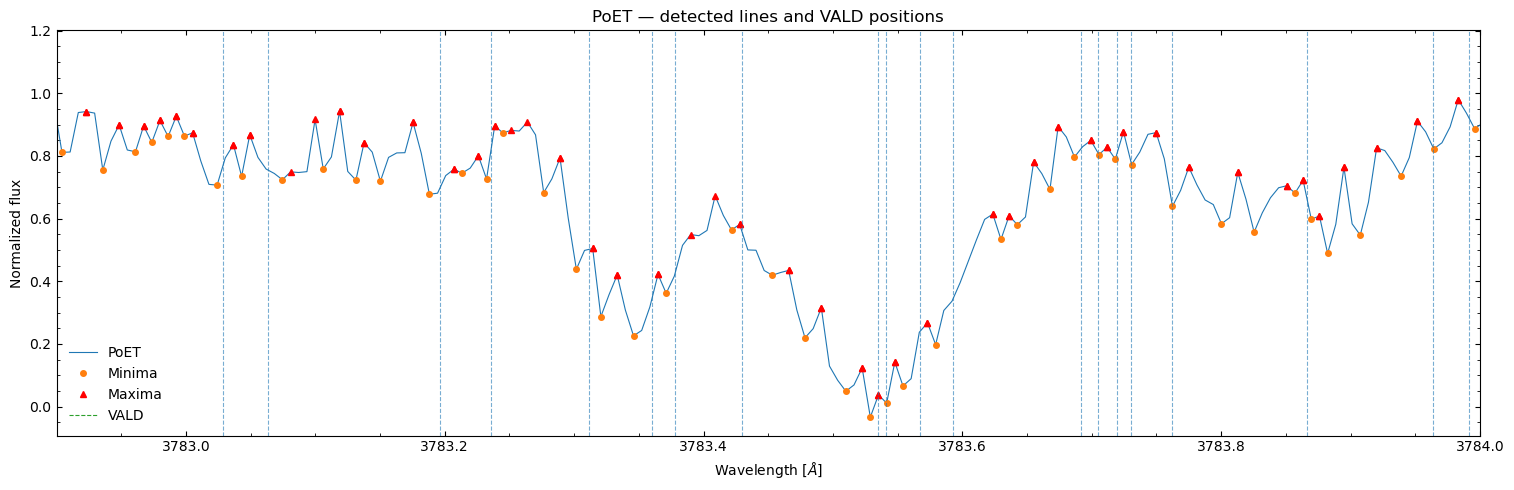

In [8]:
fig, ax = plt.subplots(figsize=(15,5))

ax.plot(wave_p, flux_p, lw=0.8, label='PoET')
ax.plot(lines_p['wave_min'], lines_p['flux_min'], 'o', ms=4, label='Minima')
ax.plot(lines_p['wave_left_max'], lines_p['flux_left_max'], '^r', ms=4, label='Maxima')
ax.plot(lines_p['wave_right_max'], lines_p['flux_right_max'], '^r', ms=4)

for wv in lines_p['vald_wave'].dropna():
    ax.axvline(wv, ls='--', lw=0.8, alpha=0.6)

ax.plot([], [], '--', lw=0.8, label='VALD')

ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel('Normalized flux')
ax.set_title('PoET — detected lines and VALD positions')
ax.legend(frameon=False)
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.minorticks_on()

plt.tight_layout()
plt.xlim(3782.9,3784)
# plt.savefig(path_figs+'Fig_min detection_POET_2.png', bbox_inches='tight', dpi=1000)
plt.show()

/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_85377/2282929364.py:20: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_85377/2282929364.py:22: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(path_figs+'Fig_min detection_POET.png', bbox_inches='tight', dpi=1000)


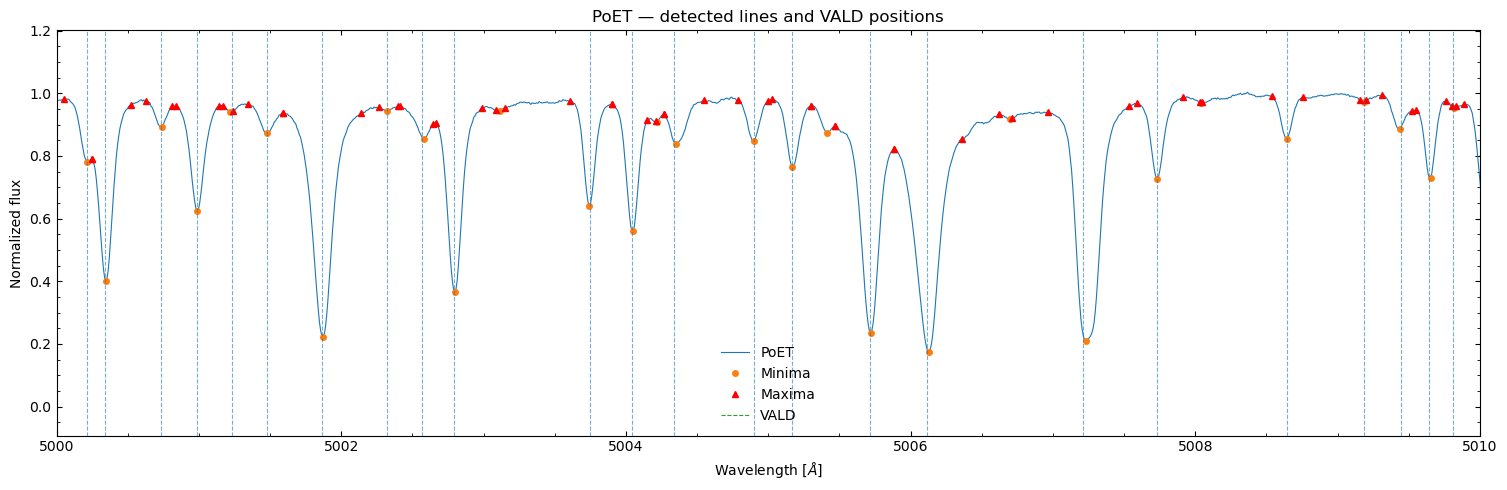

In [9]:
fig, ax = plt.subplots(figsize=(15,5))

ax.plot(wave_p, flux_p, lw=0.8, label='PoET')
ax.plot(lines_p['wave_min'], lines_p['flux_min'], 'o', ms=4, label='Minima')
ax.plot(lines_p['wave_left_max'], lines_p['flux_left_max'], '^r', ms=4, label='Maxima')
ax.plot(lines_p['wave_right_max'], lines_p['flux_right_max'], '^r', ms=4)

for wv in lines_p['vald_wave'].dropna():
    ax.axvline(wv, ls='--', lw=0.8, alpha=0.6)

ax.plot([], [], '--', lw=0.8, label='VALD')

ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel('Normalized flux')
ax.set_title('PoET — detected lines and VALD positions')
ax.legend(frameon=False)
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.minorticks_on()

plt.tight_layout()
plt.xlim(5000,5010)
plt.savefig(path_figs+'Fig_min detection_POET.png', bbox_inches='tight', dpi=1000)
plt.show()

/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_85377/221576169.py:20: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_85377/221576169.py:22: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(path_figs+'Fig_min detection_MURAM.png', bbox_inches='tight', dpi=1000)


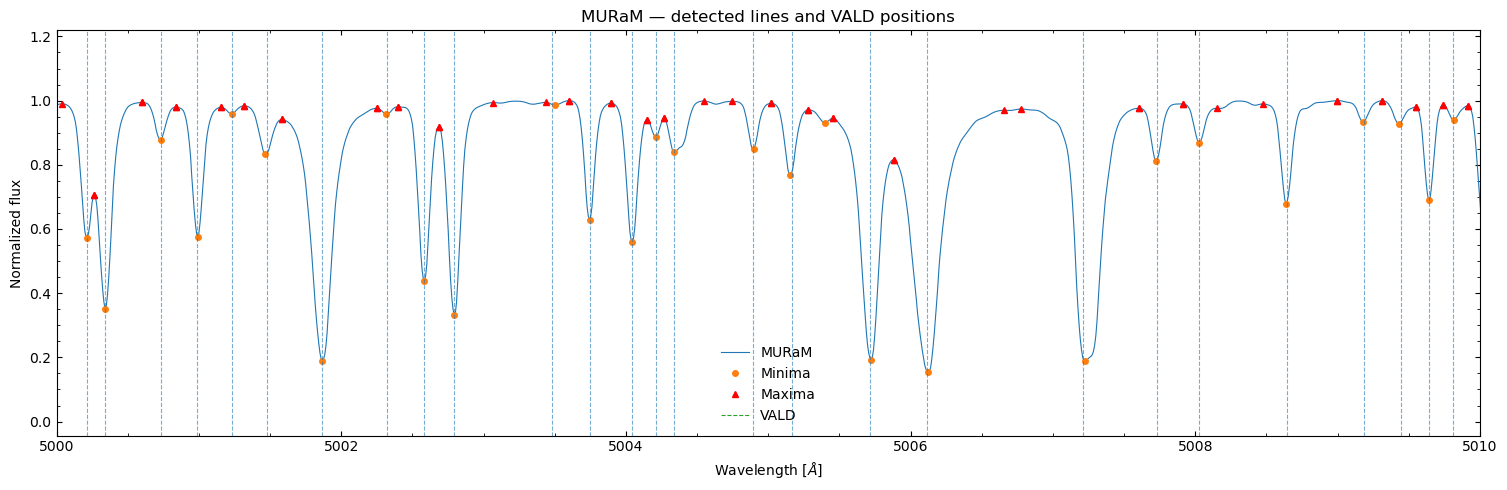

In [10]:
fig, ax = plt.subplots(figsize=(15,5))

ax.plot(wave, flux, lw=0.8, label='MURaM')
ax.plot(lines['wave_min'], lines['flux_min'], 'o', ms=4, label='Minima')
ax.plot(lines['wave_left_max'], lines['flux_left_max'], '^r', ms=4, label='Maxima')
ax.plot(lines['wave_right_max'], lines['flux_right_max'], '^r', ms=4)

for wv in lines['vald_wave'].dropna():
    ax.axvline(wv, ls='--', lw=0.8, alpha=0.6)

ax.plot([], [], '--', lw=0.8, label='VALD')

ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel('Normalized flux')
ax.set_title('MURaM — detected lines and VALD positions')
ax.legend(frameon=False)
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.minorticks_on()

plt.tight_layout()
plt.xlim(5000,5010)
plt.savefig(path_figs+'Fig_min detection_MURAM.png', bbox_inches='tight', dpi=1000)

plt.show()

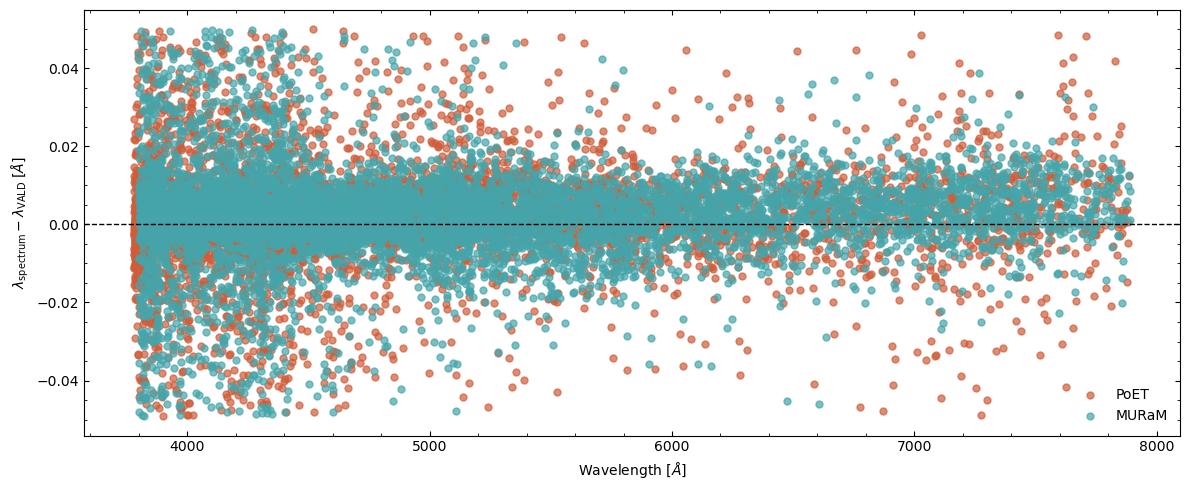

In [11]:
fig, ax = plt.subplots(figsize=(12,5))

m_p = lines_p['vald_wave'].notna()
m = lines['vald_wave'].notna()

ax.scatter(lines_p.loc[m_p,'vald_wave'], lines_p.loc[m_p,'wave_min']-lines_p.loc[m_p,'vald_wave'], s=25, alpha=0.7, label='PoET', color="#cf5d3a")
ax.scatter(lines.loc[m,'vald_wave'], lines.loc[m,'wave_min']-lines.loc[m,'vald_wave'], s=25, alpha=0.7, label='MURaM', color="#45a5aa")

ax.axhline(0, color='k', ls='--', lw=1)

ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel(r'$\lambda_{\rm spectrum}-\lambda_{\rm VALD}$ [$\AA$]')
ax.legend(frameon=False)
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.minorticks_on()

plt.tight_layout()
plt.savefig(path_figs+'Fig_dwv_VALD.png', bbox_inches='tight', dpi=1000)

plt.show()

In [ ]:
m_p = lines_p['vald_depth'].notna()
m_l = lines['vald_depth'].notna()

lines_p['d_depth_vald'] = lines_p.loc[m_p,'depth']-lines_p.loc[m_p,'vald_depth']
lines['d_depth_vald'] = lines.loc[m_l,'depth']-lines.loc[m_l,'vald_depth']

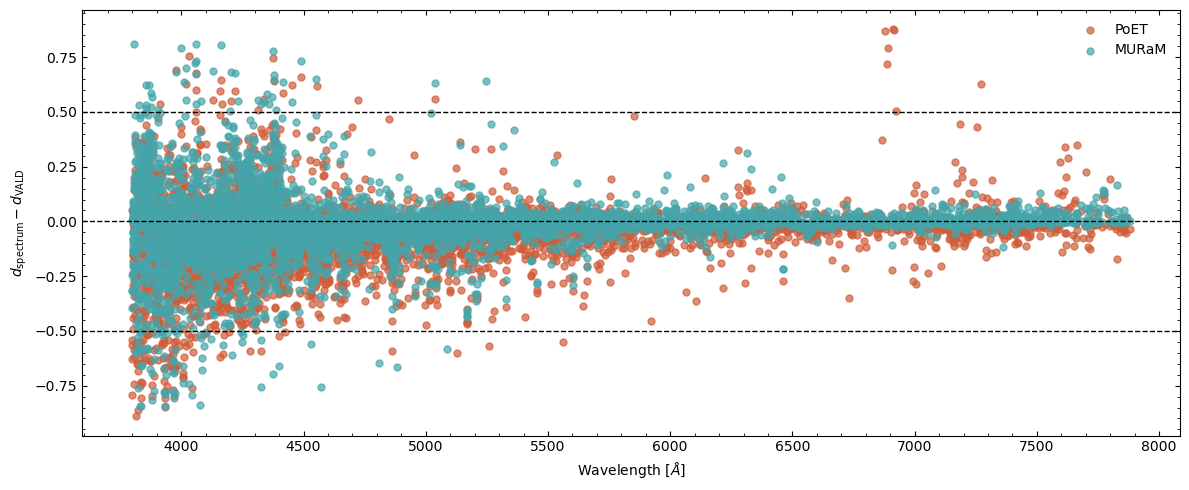

In [ ]:
fig, ax = plt.subplots(figsize=(12,5))

m_p = lines_p['vald_depth'].notna()
m_l = lines['vald_depth'].notna()

ax.scatter(lines_p.loc[m_p,'vald_wave'], lines_p['d_depth_vald'], s=25, alpha=0.7, label='PoET', color="#cf5d3a")
ax.scatter(lines.loc[m_l,'vald_wave'], lines['d_depth_vald'], s=25, alpha=0.7, label='MURaM', color="#45a5aa")

ax.axhline(0, color='k', ls='--', lw=1)


ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel(r'$d_{\rm spectrum}-d_{\rm VALD}$')
ax.legend(frameon=False)
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.minorticks_on()

plt.tight_layout()
plt.savefig(path_figs+'Fig_ddepth_VALD.png', bbox_inches='tight', dpi=1000)

plt.show()

#TODO look at the 10 with huge delta in positive and negative, maybe tellurics lines?
#histogram of delta depth for the list of candidates + combined with nbr of line after removing delta depth < 0.5 

depth tolerance (sigma of d_depth): PoET 0.267, MURaM 0.260


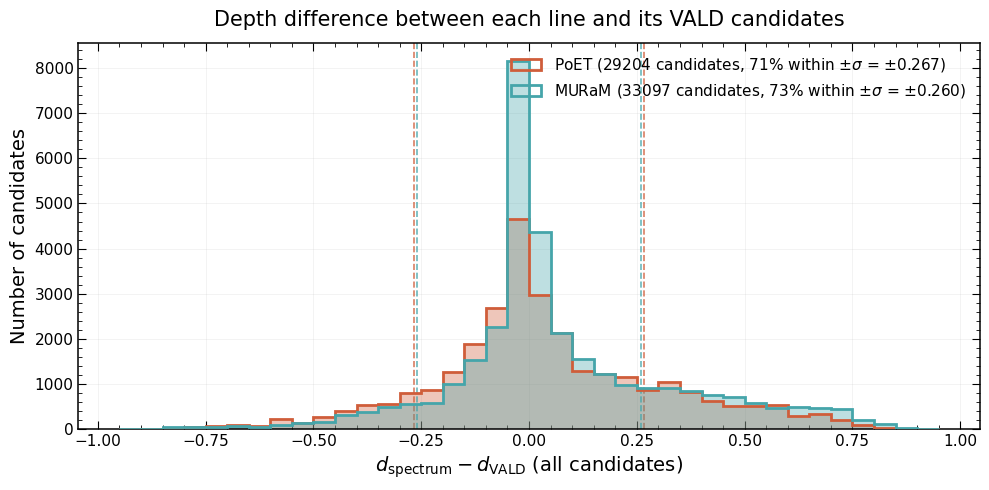

In [16]:
# Depth difference between every detected line and each of its VALD candidates (not only the best match)

def candidate_d_depth(lines_df):
    """One row per (line, candidate): d_depth = depth of the line - VALD depth of the candidate."""
    rows = []
    for i_line, (depth, cands) in enumerate(zip(lines_df['depth'], lines_df['candidates'])):
        for j in cands:
            rows.append({'line': i_line, 'vald_index': df_vald.index[j], 'd_depth': depth - depth_vald[j]})
    return pd.DataFrame(rows, columns=['line', 'vald_index', 'd_depth'])

# all the lines detected in PoET and in MURaM (before any selection)
cand_p = candidate_d_depth(lines_p_raw)
cand = candidate_d_depth(lines_raw)

# depth tolerance = sigma (standard deviation) of the depth difference distribution of every spectrum
depth_tolerance = {'PoET': np.std(cand_p['d_depth']), 'MURaM': np.std(cand['d_depth'])}
print('depth tolerance (sigma of d_depth): PoET %.3f, MURaM %.3f' % (depth_tolerance['PoET'], depth_tolerance['MURaM']))

dd_all = np.concatenate([cand_p['d_depth'], cand['d_depth']])
step = 0.05
bins_dd = np.arange(np.floor(dd_all.min() / step) * step, np.ceil(dd_all.max() / step) * step + step, step)

fig, ax = plt.subplots(figsize=(10,5))

for c, label, color in [(cand_p, 'PoET', "#cf5d3a"), (cand, 'MURaM', "#45a5aa")]:
    d = c['d_depth']
    ax.hist(d, bins=bins_dd, color=color, alpha=0.35, zorder=2)
    ax.hist(d, bins=bins_dd, histtype='step', lw=2, color=color, zorder=3,
            label=f'{label} ({len(d)} candidates, {np.mean(np.abs(d) < depth_tolerance[label]) * 100:.0f}% within $\\pm\\sigma$ = $\\pm${depth_tolerance[label]:.3f})')
    for x in (-depth_tolerance[label], depth_tolerance[label]):
        ax.axvline(x, color=color, ls='--', lw=1.2, alpha=0.8)

ax.set_xlabel(r'$d_{\rm spectrum}-d_{\rm VALD}$ (all candidates)', fontsize=14)
ax.set_ylabel('Number of candidates', fontsize=14)
ax.set_title('Depth difference between each line and its VALD candidates', fontsize=15, pad=12)
# ax.set_yscale('log')  # uncomment if the tail is hard to see

ax.legend(frameon=False, fontsize=11)

ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
ax.minorticks_on()

ax.grid(alpha=0.15, linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

depth cut: |d_depth| < 0.260 (smallest sigma: PoET 0.267, MURaM 0.260)
PoET: 10597 lines, 6181 keep at least one candidate, 4416 lose all of them
MURaM: 7936 lines, 7016 keep at least one candidate, 920 lose all of them


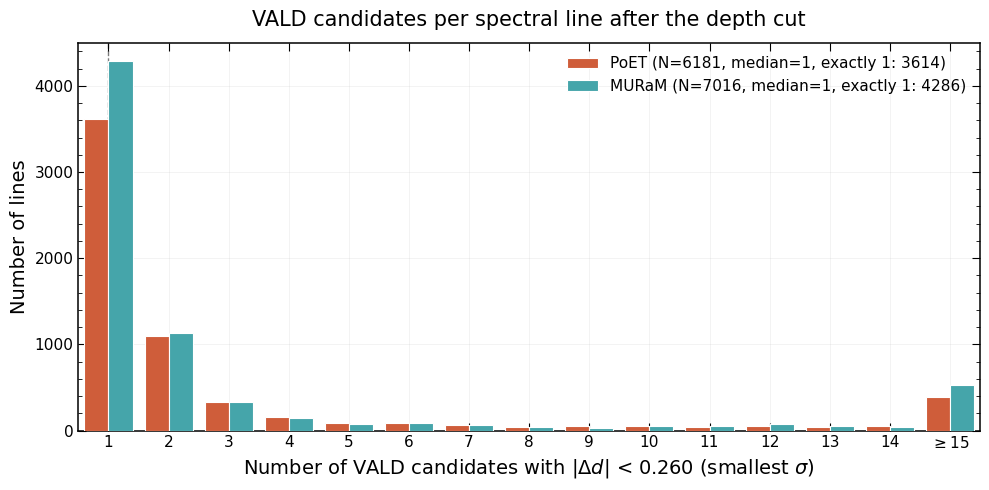

In [17]:
# Number of VALD candidates per line, keeping only the candidates with |d_depth| < the smallest sigma of the depth
# difference distributions of the two spectra (the same cut for both)
depth_tolerance_cut = min(depth_tolerance.values())
print('depth cut: |d_depth| < %.3f (smallest sigma: PoET %.3f, MURaM %.3f)'
      % (depth_tolerance_cut, depth_tolerance['PoET'], depth_tolerance['MURaM']))
for lines_df, c in [(lines_p_raw, cand_p), (lines_raw, cand)]:
    kept = c.loc[np.abs(c['d_depth']) < depth_tolerance_cut, 'line'].value_counts()
    lines_df['n_vald_candidates_depth'] = kept.reindex(np.arange(len(lines_df)), fill_value=0).values

n_max = 15  # lines with n_max or more candidates go in the last bin
bins = np.arange(0.5, n_max + 1.5, 1)

centres = np.arange(1, n_max + 1)
width = 0.4  # each bar takes 0.4 of the unit bin, leaving a small gap between groups

fig, ax = plt.subplots(figsize=(10,5))

for k, (df, label, color) in enumerate([(lines_p_raw, 'PoET', "#cf5d3a"), (lines_raw, 'MURaM', "#45a5aa")]):
    # only the lines that keep at least one candidate after the cut
    n = df['n_vald_candidates_depth']
    print('%s: %d lines, %d keep at least one candidate, %d lose all of them'
          % (label, len(n), np.sum(n > 0), np.sum(n == 0)))
    n = n[n > 0]
    counts, _ = np.histogram(np.minimum(n, n_max), bins=bins)
    offset = (k - 0.5) * width  # PoET left of the integer, MURaM right
    ax.bar(centres + offset, counts, width=width, color=color, edgecolor='white', linewidth=0.8, zorder=3,
           label=f'{label} (N={len(n)}, median={np.median(n):.0f}, exactly 1: {np.sum(n == 1)})')

ax.axvline(1, color='k', ls='--', lw=1, alpha=0.5)

ax.set_xlabel(f'Number of VALD candidates with $|\\Delta d|$ < {depth_tolerance_cut:.3f} (smallest $\\sigma$)', fontsize=14)
ax.set_ylabel('Number of lines', fontsize=14)
ax.set_title('VALD candidates per spectral line after the depth cut', fontsize=15, pad=12)
ax.set_xlim(bins[0], bins[-1])
# ax.set_yscale('log')  # uncomment if the tail is hard to see

ax.legend(frameon=False, fontsize=11)

ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks(centres)
ax.set_xticklabels([str(c) for c in centres[:-1]] + [f'$\\geq${n_max}'])

ax.grid(alpha=0.15, linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

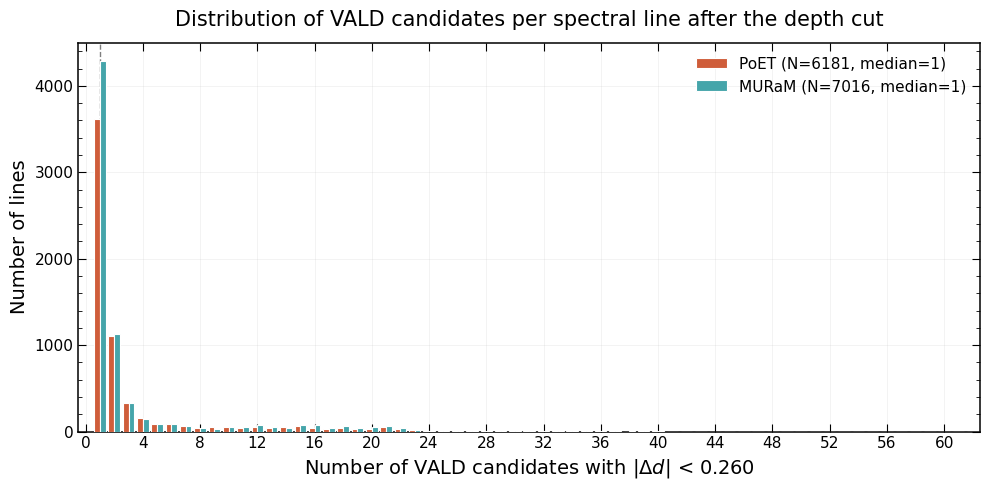

In [18]:
# Same figure as the first histogram (same bins and x range), but after the depth cut: number of VALD candidates with
# |d_depth| < depth_tolerance_cut, for the lines that keep at least one candidate
# One bin per integer count, centred on the integer
n_max = int(max(lines_p_raw['n_vald_candidates'].max(), lines_raw['n_vald_candidates'].max()))
bins = np.arange(-0.5, n_max + 1.5, 1)

centres = np.arange(0, n_max + 1)
width = 0.4  # each bar takes 0.4 of the unit bin, leaving a small gap between groups

fig, ax = plt.subplots(figsize=(10,5))

for k, (df, label, color) in enumerate([(lines_p_raw, 'PoET', "#cf5d3a"), (lines_raw, 'MURaM', "#45a5aa")]):
    n = df['n_vald_candidates_depth']
    n = n[n > 0]
    counts, _ = np.histogram(n, bins=bins)
    offset = (k - 0.5) * width  # PoET left of the integer, MURaM right
    ax.bar(centres + offset, counts, width=width, color=color, edgecolor='white', linewidth=0.8, zorder=3,
           label=f'{label} (N={len(n)}, median={np.median(n):.0f})')

ax.axvline(1, color='k', ls='--', lw=1, alpha=0.5)

ax.set_xlabel(f'Number of VALD candidates with $|\\Delta d|$ < {depth_tolerance_cut:.3f}', fontsize=14)
ax.set_ylabel('Number of lines', fontsize=14)
ax.set_title('Distribution of VALD candidates per spectral line after the depth cut', fontsize=15, pad=12)
ax.set_xlim(bins[0], bins[-1])
# ax.set_yscale('log')  # uncomment if the tail is hard to see

ax.legend(frameon=False, fontsize=11)

ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks(centres if n_max <= 30 else centres[::max(1, n_max // 15)])

ax.grid(alpha=0.15, linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

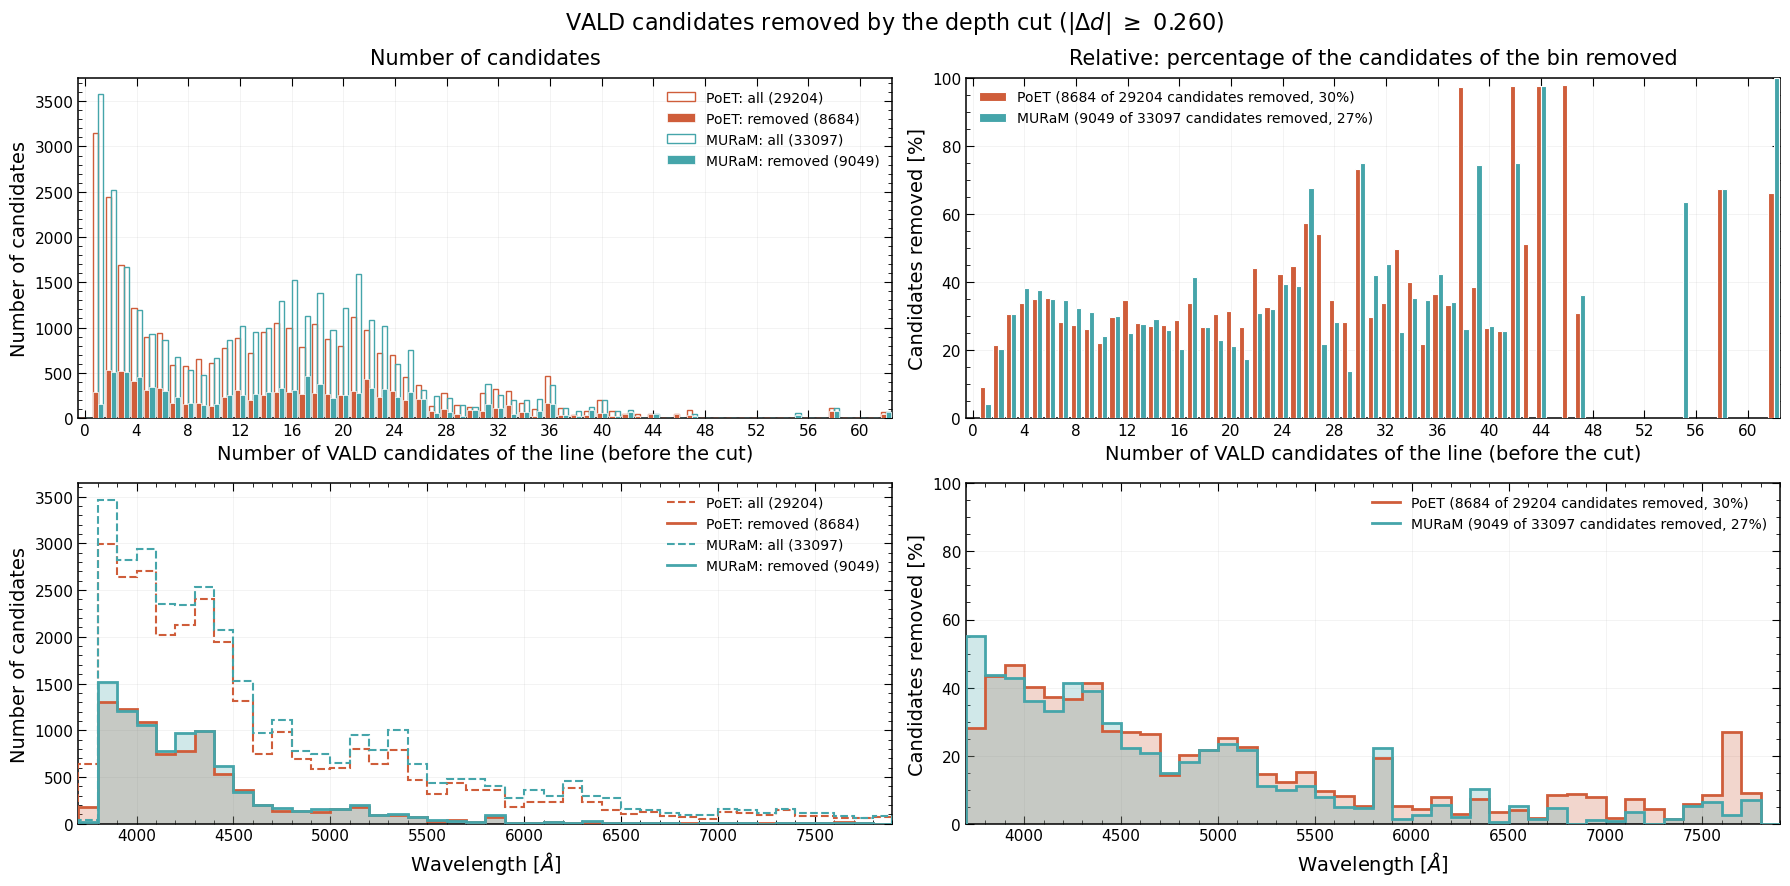

In [ ]:
# Candidates removed by the depth cut (|d_depth| >= depth_tolerance_cut), for PoET and MURaM
#   left:   number of candidates (open: all the candidates before the cut, filled: removed by the cut)
#   right:  relative, percentage of the candidates of the bin removed by the cut
#   top:    vs the number of VALD candidates of the line before the cut
#   bottom: vs wavelength (wavelength of the detected line)
step_wave = 100       # [A] width of the wavelength bins

fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, figsize=(18, 9))

n_max = int(max(lines_p_raw['n_vald_candidates'].max(), lines_raw['n_vald_candidates'].max()))
centres = np.arange(0, n_max + 1)
width = 0.4

w_all = np.concatenate([lines_p_raw['wave_min'], lines_raw['wave_min']])
bins_w = np.arange(np.floor(w_all.min() / step_wave) * step_wave, np.ceil(w_all.max() / step_wave) * step_wave + step_wave, step_wave)

for k, (df, c, label, color) in enumerate([(lines_p_raw, cand_p, 'PoET', "#cf5d3a"), (lines_raw, cand, 'MURaM', "#45a5aa")]):
    lost = (np.abs(c['d_depth']) >= depth_tolerance_cut).values
    n_line = df['n_vald_candidates'].values[c['line'].values]      # number of candidates of the line before the cut
    w_line = df['wave_min'].values[c['line'].values]               # wavelength of the line
    lab = f'{label} ({lost.sum()} of {len(lost)} candidates removed, {lost.mean() * 100:.0f}%)'

    # vs the number of candidates before the cut
    tot = np.bincount(n_line, minlength=n_max + 1)
    rem = np.bincount(n_line, weights=lost, minlength=n_max + 1)
    frac = np.full(n_max + 1, np.nan)
    frac[tot > 0] = rem[tot > 0] / tot[tot > 0] * 100
    x = centres + (k - 0.5) * width
    ax1.bar(x, tot, width=width, facecolor='none', edgecolor=color, linewidth=1.0, zorder=3,
            label=f'{label}: all ({len(lost)})')
    ax1.bar(x, rem, width=width, color=color, edgecolor='white', linewidth=0.5, zorder=4,
            label=f'{label}: removed ({lost.sum()})')
    ax3.bar(x, frac, width=width, color=color, edgecolor='white', linewidth=0.8, zorder=3, label=lab)

    # vs wavelength
    tot_w, _ = np.histogram(w_line, bins=bins_w)
    rem_w, _ = np.histogram(w_line[lost], bins=bins_w)
    frac_w = np.where(tot_w > 0, rem_w / np.maximum(tot_w, 1) * 100, np.nan)
    ax2.stairs(tot_w, bins_w, color=color, lw=1.5, ls='--', zorder=3, label=f'{label}: all ({len(lost)})')
    ax2.stairs(rem_w, bins_w, color=color, lw=2, zorder=3, label=f'{label}: removed ({lost.sum()})')
    ax2.stairs(rem_w, bins_w, color=color, alpha=0.25, fill=True, zorder=2)
    ax4.stairs(frac_w, bins_w, color=color, lw=2, zorder=3, label=lab)
    ax4.stairs(frac_w, bins_w, color=color, alpha=0.25, fill=True, zorder=2)

fig.suptitle(f'VALD candidates removed by the depth cut ($|\\Delta d|$ $\\geq$ {depth_tolerance_cut:.3f})', fontsize=16)
ax1.set_title('Number of candidates', fontsize=15, pad=10)
ax3.set_title('Relative: percentage of the candidates of the bin removed', fontsize=15, pad=10)

for ax in (ax1, ax3):
    ax.set_xlabel('Number of VALD candidates of the line (before the cut)', fontsize=14)
    ax.set_xlim(-0.5, n_max + 0.5)
    ax.set_xticks(centres if n_max <= 30 else centres[::max(1, n_max // 15)])
for ax in (ax2, ax4):
    ax.set_xlabel(r'Wavelength [$\AA$]', fontsize=14)
    ax.set_xlim(bins_w[0], bins_w[-1])
for ax in (ax1, ax2):
    ax.set_ylabel('Number of candidates', fontsize=14)
    ax.set_ylim(bottom=0)
for ax in (ax3, ax4):
    ax.set_ylabel('Candidates removed [%]', fontsize=14)
    ax.set_ylim(0, 100)

for ax in (ax1, ax2, ax3, ax4):
    ax.legend(frameon=False, fontsize=10)
    ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
    ax.minorticks_on()
    ax.grid(alpha=0.15, linewidth=0.7)
    for spine in ax.spines.values():
        spine.set_linewidth(1.1)
for ax in (ax1, ax3):
    ax.xaxis.set_minor_locator(plt.NullLocator())

plt.tight_layout()
plt.show()

#todo correlation for candidate nbr=1 line depth vs delta depth


In [14]:
# lines_p = lines_p[lines_p['vald_depth'].notna() & (np.abs(lines_p['depth']-lines_p['vald_depth']) <= depth_tolerance)].reset_index(drop=True)

# lines = lines[lines['vald_depth'].notna() & (np.abs(lines['depth']-lines['vald_depth']) <= depth_tolerance)].reset_index(drop=True)

In [21]:
# Common lines of PoET and MURaM: a PoET line and a MURaM line are the same line if their lists of VALD candidates
# share at least one VALD line (not only if they chose the same best VALD line).
def common_lines(tab, rows):
    """Rows of a line table for the pairs, with the common VALD line of every pair."""
    out = tab.iloc[[r for r, _ in rows]].copy().reset_index(drop=True)
    vald = [v for _, v in rows]
    out['vald_index_best'] = out['vald_index']            # VALD line chosen by find_spectral_lines alone
    out['vald_index'] = df_vald.index[vald]
    out['vald_wave'] = wave_vald[vald]
    out['vald_depth'] = depth_vald[vald]
    out['delta_vald'] = out['wave_min'] - out['vald_wave']
    return out

def pair_common_lines(lp, lm):
    """Common lines of the PoET (lp) and MURaM (lm) line tables: the same order in both tables (row k of the two
    tables is the same line), sorted by the common VALD line."""
    # MURaM lines containing every VALD candidate
    muram_with = {}
    for j, cand in enumerate(lm['candidates']):
        for v in np.atleast_1d(cand):
            muram_with.setdefault(int(v), []).append(j)

    # all the possible pairs (PoET line, MURaM line) with at least one common candidate, closest minima first
    pairs = []
    for i_p, cand in enumerate(lp['candidates']):
        for j in {j for v in np.atleast_1d(cand) for j in muram_with.get(int(v), [])}:
            pairs.append((abs(lp['wave_min'].iloc[i_p] - lm['wave_min'].iloc[j]), i_p, j))
    pairs.sort()

    # one-to-one pairing, and one common VALD line per pair
    used_p, used_m, used_vald, matched_pairs = set(), set(), set(), []
    for _, i_p, j in pairs:
        if i_p in used_p or j in used_m:
            continue
        shared = np.intersect1d(np.atleast_1d(lp['candidates'].iloc[i_p]), np.atleast_1d(lm['candidates'].iloc[j])).astype(int)
        best_p, best_m = lp['vald_index'].iloc[i_p], lm['vald_index'].iloc[j]
        if best_p == best_m:                                   # same best VALD line: keep it
            v = int(np.where(df_vald.index == best_p)[0][0])
        else:                                                  # the shared candidate closest to the two minima (unused ones first)
            w_mid = 0.5 * (lp['wave_min'].iloc[i_p] + lm['wave_min'].iloc[j])
            order = shared[np.argsort(np.abs(wave_vald[shared] - w_mid))]
            free = [s for s in order if s not in used_vald]
            v = int(free[0] if free else order[0])
        used_p.add(i_p); used_m.add(j); used_vald.add(v)
        matched_pairs.append((i_p, j, v))

    out_p = common_lines(lp, [(i_p, v) for i_p, _, v in matched_pairs])
    out_m = common_lines(lm, [(j, v) for _, j, v in matched_pairs])
    order = np.lexsort((np.arange(len(out_p)), out_p['vald_index'].values))
    return out_p.iloc[order].reset_index(drop=True), out_m.iloc[order].reset_index(drop=True)

n_old = len(np.intersect1d(lines_p['vald_index'].values, lines['vald_index'].values))   # previous method, for comparison
lines_p, lines = pair_common_lines(lines_p, lines)

print('common lines: %d with a shared VALD candidate (%d with the same best VALD line only)' % (len(lines_p), n_old))
print('pairs whose best VALD lines differed: %d' % np.sum(lines_p['vald_index_best'].values != lines['vald_index_best'].values))
print('pairs sharing their VALD line with another pair: %d' % (len(lines_p) - lines_p['vald_index'].nunique()))

common lines: 5779 with a shared VALD candidate (4413 with the same best VALD line only)
pairs whose best VALD lines differed: 1369
pairs sharing their VALD line with another pair: 0


In [16]:
def compute_line_weights(wave, flux, lines, sigma=0):
    derivative = np.gradient(flux,wave)
    weight = wave**2*derivative**2/(flux+sigma**2)

    line_weights = []

    for _, line in lines.iterrows():
        i_left = int(line['i_left'])
        i_right = int(line['i_right'])
        line_weights.append(np.sum(weight[i_left:i_right+1]))

    lines = lines.copy()
    lines['weight'] = line_weights

    return lines

In [17]:
lines_p = compute_line_weights(wave_p,flux_p,lines_p,sigma=0)
lines = compute_line_weights(wave,flux,lines,sigma=0)

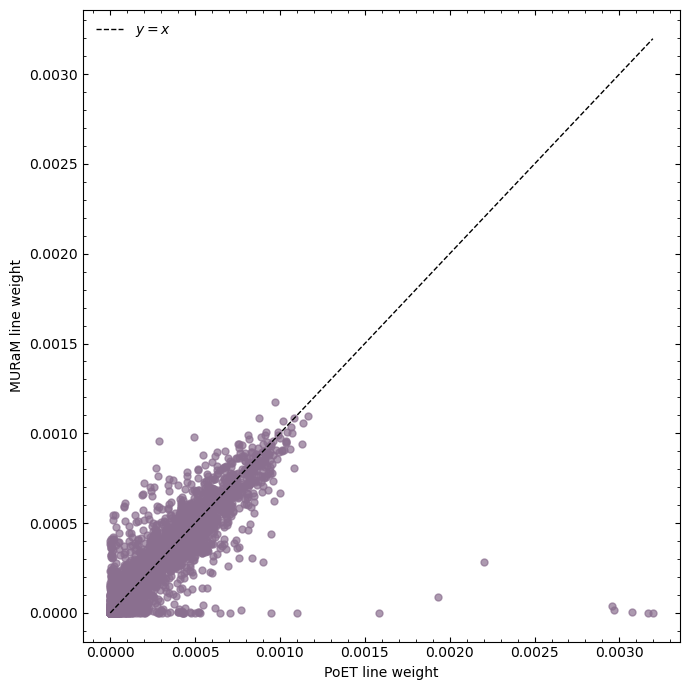

In [ ]:
fig, ax = plt.subplots(figsize=(7,7))

ax.scatter(lines_p['weight']/np.sum(lines_p['weight']),lines['weight']/np.sum(lines['weight']),s=25,alpha=0.7, color='#8A6F8F')

wmin = min(lines_p['weight'].min()/np.sum(lines_p['weight']),lines['weight'].min()/np.sum(lines['weight']))
wmax = max(lines_p['weight'].max()/np.sum(lines_p['weight']),lines['weight'].max()/np.sum(lines['weight']))

ax.plot([wmin,wmax],[wmin,wmax],'k--',lw=1,label=r'$y=x$')

ax.set_xlabel('PoET line weight')
ax.set_ylabel('MURaM line weight')

ax.tick_params(which='both',direction='in',top=True,right=True)
ax.minorticks_on()
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(path_figs+'Fig_dweight_POET_vs_MURAM.png', bbox_inches='tight', dpi=1000)

plt.show()

#tellurics?

In [19]:
check = (np.abs(lines_p['weight']/np.sum(lines_p['weight']) - lines['weight']/np.sum(lines['weight'])) > 0.001 )

In [20]:
lines['wave_min'][check]

2443    4554.016938
5287    6867.244159
5289    6876.687862
5295    6885.754091
5296    6889.878010
5302    6913.232090
5303    6914.039211
5307    6924.182371
5722    7664.914943
Name: wave_min, dtype: float64

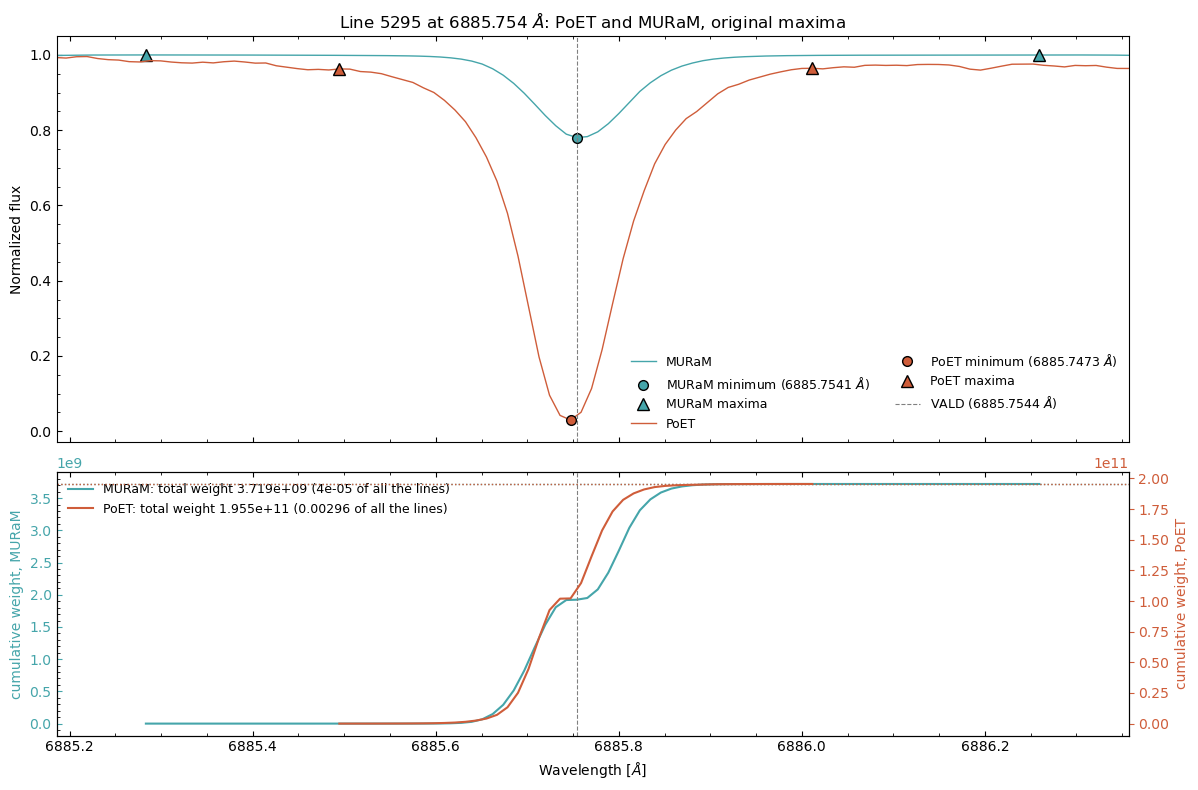

In [38]:
k = 5295      # line to plot (row of `lines` / `lines_p`, sorted by VALD index)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1.3]})
ax2b = ax2.twinx()                      # PoET cumulative weight (much larger than MURaM's): its own axis
w_lo, w_hi = np.inf, -np.inf
for name, w, f, ln, color, axc in (('MURaM', wave, flux, lines.loc[k], '#45a5aa', ax2),
                                    ('PoET', wave_p, flux_p, lines_p.loc[k], '#cf5d3a', ax2b)):
    i_left, i_right = int(ln['i_left']), int(ln['i_right'])          # original maxima
    i_min = int(np.argmin(np.abs(w - ln['wave_min'])))                # minimum
    w_lo, w_hi = min(w_lo, w[i_left]), max(w_hi, w[i_right])
    near = (w > ln['wave_min'] - 1.0) & (w < ln['wave_min'] + 1.0)
    ax.plot(w[near], f[near], '-', lw=1, color=color, label=name)
    ax.plot(w[i_min], f[i_min], 'o', ms=7, color=color, mec='k', label='%s minimum (%.4f $\\AA$)' % (name, w[i_min]))
    ax.plot(w[[i_left, i_right]], f[[i_left, i_right]], '^', ms=9, color=color, mec='k', label='%s maxima' % name)

    # cumulative weight: running sum of lambda^2 (dF/dlambda)^2 / F from the left maximum to the right one
    density = w**2 * np.gradient(f, w)**2 / f
    cumulative = np.cumsum(density[i_left:i_right+1])
    axc.plot(w[i_left:i_right+1], cumulative, '-', lw=1.5, color=color,
             label='%s: total weight %.4g (%.3g of all the lines)' % (name, cumulative[-1], cumulative[-1] / np.sum(lines['weight'] if name == 'MURaM' else lines_p['weight'])))
    axc.axhline(cumulative[-1], ls=':', lw=1, color=color)
    axc.tick_params(axis='y', colors=color)
    axc.set_ylabel('cumulative weight, %s' % name, color=color)

if np.isfinite(lines.loc[k, 'vald_wave']):
    for a in (ax, ax2):
        a.axvline(lines.loc[k, 'vald_wave'], ls='--', lw=0.8, color='grey')
    ax.plot([], [], '--', lw=0.8, color='grey', label='VALD (%.4f $\\AA$)' % lines.loc[k, 'vald_wave'])

ax.set_ylabel('Normalized flux')
ax.set_title('Line %d at %.3f $\\AA$: PoET and MURaM, original maxima' % (k, lines.loc[k, 'wave_min']))
ax.legend(frameon=False, fontsize=9, ncol=2)
ax2.set_xlabel(r'Wavelength [$\AA$]')
handles = ax2.get_legend_handles_labels()[0] + ax2b.get_legend_handles_labels()[0]
ax2.legend(handles, [h.get_label() for h in handles], frameon=False, fontsize=9, loc='upper left')
margin = 0.1 * (w_hi - w_lo)
ax.set_xlim(w_lo - margin, w_hi + margin)
for a in (ax, ax2):
    a.tick_params(which='both', direction='in', top=True)
    a.minorticks_on()

plt.tight_layout()
plt.show()

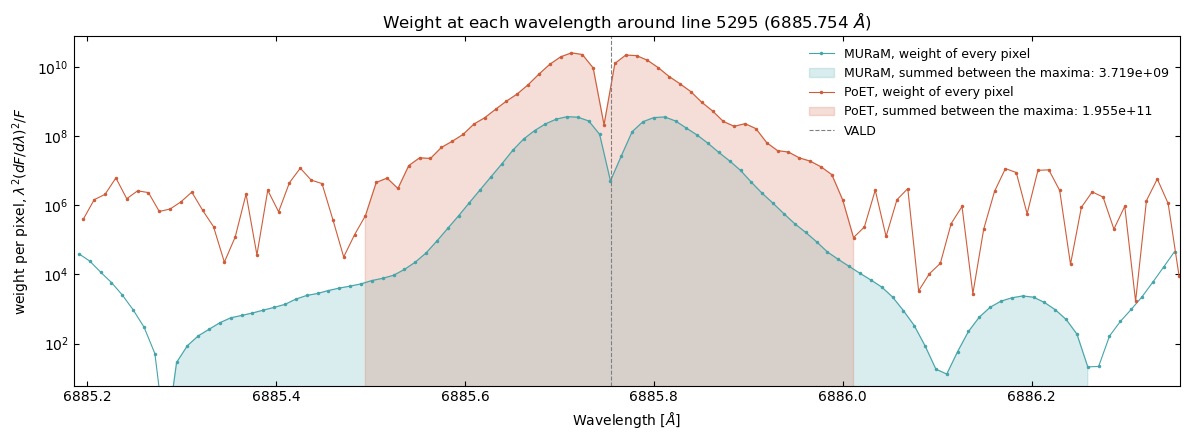

In [39]:
# Weight of every pixel, lambda^2 (dF/dlambda)^2 / F (the quantity summed between the maxima in compute_line_weights)
w_range = None          # (min, max) [A] to show another range; None = around line k

weight_pix = wave**2 * np.gradient(flux, wave)**2 / flux
weight_pix_p = wave_p**2 * np.gradient(flux_p, wave_p)**2 / flux_p

ln, ln_p = lines.loc[k], lines_p.loc[k]
if w_range is None:
    lo = min(wave[int(ln['i_left'])], wave_p[int(ln_p['i_left'])])
    hi = max(wave[int(ln['i_right'])], wave_p[int(ln_p['i_right'])])
    w_range = (lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))

fig, ax = plt.subplots(figsize=(12, 4.5))
for name, w, wp, l, color in (('MURaM', wave, weight_pix, ln, '#45a5aa'), ('PoET', wave_p, weight_pix_p, ln_p, '#cf5d3a')):
    show = (w >= w_range[0]) & (w <= w_range[1])
    ax.plot(w[show], wp[show], '.-', ms=3, lw=0.8, color=color, label='%s, weight of every pixel' % name)
    a, b = int(l['i_left']), int(l['i_right'])
    ax.fill_between(w[a:b+1], wp[a:b+1], 1e-30, color=color, alpha=0.2,
                    label='%s, summed between the maxima: %.4g' % (name, np.sum(wp[a:b+1])))
if np.isfinite(ln['vald_wave']):
    ax.axvline(ln['vald_wave'], ls='--', lw=0.8, color='grey', label='VALD')
ax.set_yscale('log')
positive = np.concatenate([weight_pix[(wave >= w_range[0]) & (wave <= w_range[1])],
                           weight_pix_p[(wave_p >= w_range[0]) & (wave_p <= w_range[1])]])
positive = positive[positive > 0]
ax.set_ylim(np.percentile(positive, 1) / 3, positive.max() * 3)
ax.set_xlim(*w_range)
ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel(r'weight per pixel, $\lambda^2 (dF/d\lambda)^2 / F$')
ax.set_title('Weight at each wavelength around line %d (%.3f $\\AA$)' % (k, ln['wave_min']))
ax.legend(frameon=False, fontsize=9)
ax.tick_params(which='both', direction='in', top=True, right=True)
plt.tight_layout()
plt.show()

In [23]:
# Read ESPRESSO mask
df_mask = pd.read_csv(path_data_out+'SUN_LINELIST_MASK.csv')

wave_mask = df_mask['wave'].values
contrast_mask = df_mask['cont'].values

# Compute weights
weight_mask = contrast_mask**2

# Normalize so sum(weights) = N_lines
Nline_mask = len(wave_mask)
weight_mask *= Nline_mask/np.sum(weight_mask)

# Add weights to dataframe
df_mask['weight'] = weight_mask

# Check normalization
print('N lines     =',Nline_mask)
print('Sum weights =',np.sum(weight_mask))

N lines     = 3297
Sum weights = 3297.0


In [24]:
tolerance_mask = 0.11

matched = []

for j in range(len(df_mask)):
    d = np.abs(lines_p['vald_wave'].values-df_mask.loc[j,'wave'])
    k = np.argmin(d)

    if d[k] <= tolerance_mask:
        matched.append({'espresso_index': j, 'common_index': k, 'wave_espresso': df_mask.loc[j,'wave'], 'weight_espresso': df_mask.loc[j,'weight'], 'wave_vald': lines_p.loc[k,'vald_wave'], 'wave_poet': lines_p.loc[k,'wave_min'], 'wave_muram': lines.loc[k,'wave_min'], 'weight_poet': lines_p.loc[k,'weight'], 'weight_muram': lines.loc[k,'weight']})

matched = pd.DataFrame(matched)
print('Number of matched lines:',len(matched))

Number of matched lines: 3045


In [25]:
print('Duplicate ESPRESSO lines:',matched['espresso_index'].duplicated().any())
print('Duplicate common lines:',matched['common_index'].duplicated().any())

Duplicate ESPRESSO lines: False
Duplicate common lines: False


In [26]:
print('PoET duplicated VALD:',lines_p['vald_index'].duplicated().any())
print('MURaM duplicated VALD:',lines['vald_index'].duplicated().any())
print('Same number of lines:',len(lines_p)==len(lines))
print('Same VALD lines:',np.array_equal(lines_p['vald_index'].values,lines['vald_index'].values))

PoET duplicated VALD: False
MURaM duplicated VALD: False
Same number of lines: True
Same VALD lines: True


In [27]:
matched['weight_espresso_norm'] = matched['weight_espresso']/matched['weight_espresso'].sum()*len(matched)
matched['weight_poet_norm'] = matched['weight_poet']/matched['weight_poet'].sum()*len(matched)
matched['weight_muram_norm'] = matched['weight_muram']/matched['weight_muram'].sum()*len(matched)

print('ESPRESSO:',matched['weight_espresso_norm'].sum())
print('PoET:    ',matched['weight_poet_norm'].sum())
print('MURaM:   ',matched['weight_muram_norm'].sum())

ESPRESSO: 3045.0
PoET:     3044.9999999999995
MURaM:    3045.0


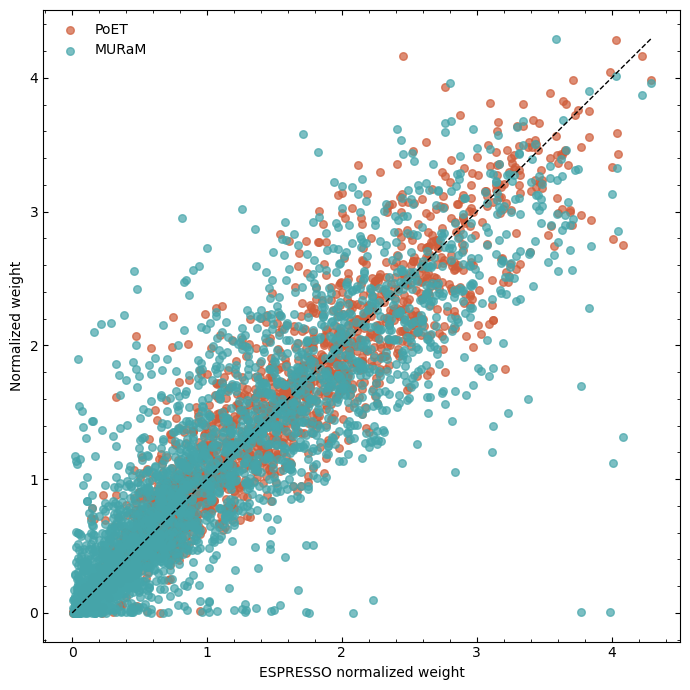

In [ ]:
fig, ax = plt.subplots(figsize=(7,7))

ax.scatter(matched['weight_espresso_norm'],matched['weight_poet_norm'],s=30,alpha=0.7,label='PoET', color="#cf5d3a")
ax.scatter(matched['weight_espresso_norm'],matched['weight_muram_norm'],s=30,alpha=0.7,label='MURaM', color="#45a5aa")

wmax = np.max([matched['weight_espresso_norm'].max(),matched['weight_poet_norm'].max(),matched['weight_muram_norm'].max()])
ax.plot([0,wmax],[0,wmax],'k--',lw=1)

ax.set_xlabel('ESPRESSO normalized weight')
ax.set_ylabel('Normalized weight')

ax.tick_params(which='both',direction='in',top=True,right=True)
ax.minorticks_on()
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(path_figs+'Fig_dweight_vs_ESPRESSO.png', bbox_inches='tight', dpi=1000)

plt.show()

#TODO look at smal weight for muram

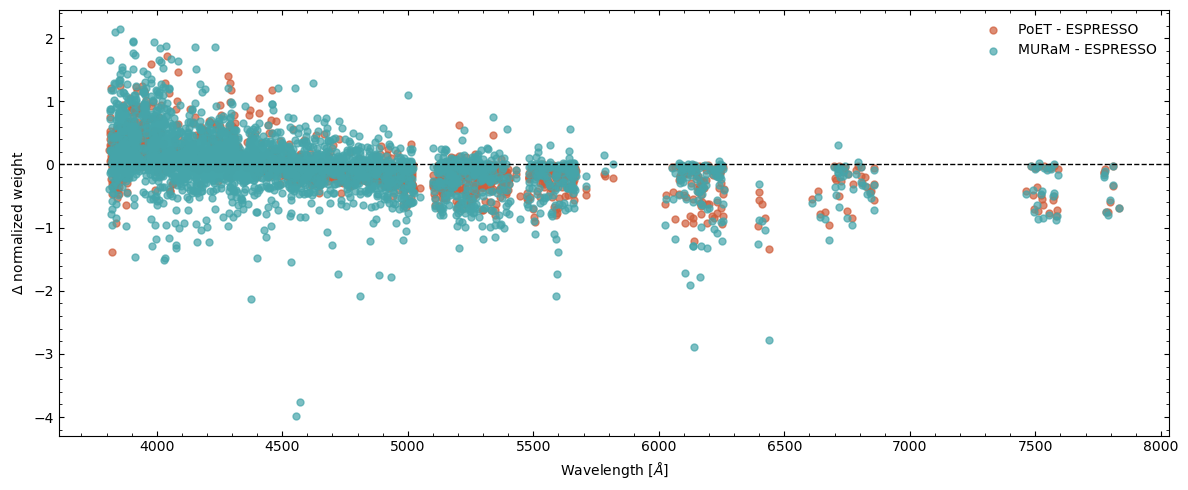

In [29]:
matched['delta_weight_poet'] = matched['weight_poet_norm']-matched['weight_espresso_norm']
matched['delta_weight_muram'] = matched['weight_muram_norm']-matched['weight_espresso_norm']

fig, ax = plt.subplots(figsize=(12,5))

ax.scatter(matched['wave_espresso'],matched['delta_weight_poet'],s=25,alpha=0.7,label='PoET - ESPRESSO', color="#cf5d3a")
ax.scatter(matched['wave_espresso'],matched['delta_weight_muram'],s=25,alpha=0.7,label='MURaM - ESPRESSO', color="#45a5aa")

ax.axhline(0,color='k',ls='--',lw=1)

ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel(r'$\Delta$ normalized weight')

ax.tick_params(which='both',direction='in',top=True,right=True)
ax.minorticks_on()
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(path_figs+'Fig_dweight(wv)_vs_ESPRESSO.png', bbox_inches='tight', dpi=1000)

plt.show()

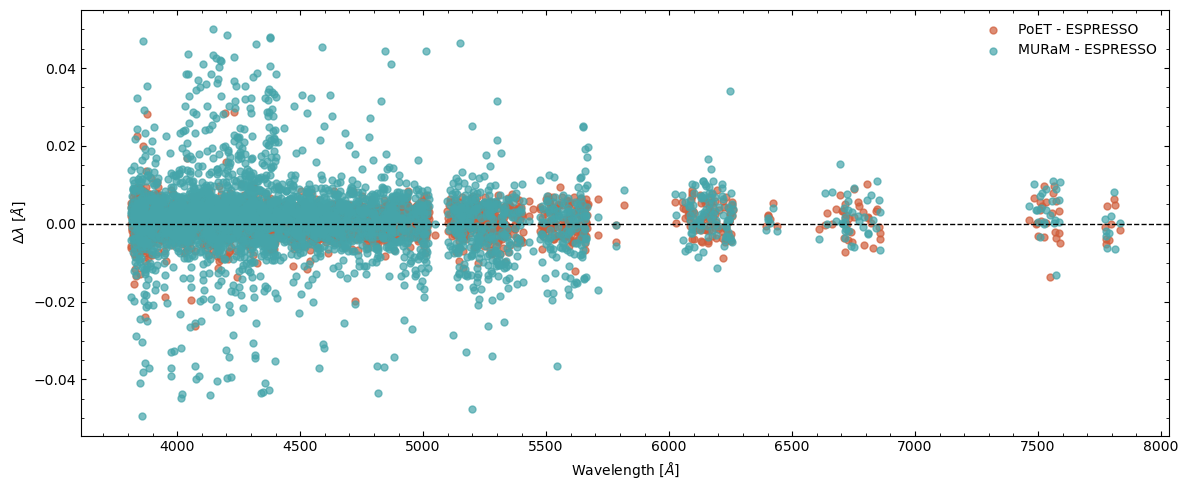

In [61]:
matched['delta_wave_poet'] = matched['wave_poet']-matched['wave_espresso']
matched['delta_wave_muram'] = matched['wave_muram']-matched['wave_espresso']

fig, ax = plt.subplots(figsize=(12,5))

ax.scatter(matched['wave_espresso'],matched['delta_wave_poet'],s=25,alpha=0.7,label='PoET - ESPRESSO', color="#cf5d3a")
ax.scatter(matched['wave_espresso'],matched['delta_wave_muram'],s=25,alpha=0.7,label='MURaM - ESPRESSO', color="#45a5aa")

ax.axhline(0,color='k',ls='--',lw=1)
# ax.axhline(0.05,color='k',ls='--',lw=1)
# ax.axhline(-0.05,color='k',ls='--',lw=1)


ax.set_xlabel(r'Wavelength [$\AA$]')
ax.set_ylabel(r'$\Delta\lambda$ [$\AA$]')

ax.tick_params(which='both',direction='in',top=True,right=True)
ax.minorticks_on()
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(path_figs+'Fig_dwv_vs_ESPRESSO.png', bbox_inches='tight', dpi=1000)

plt.show()

In [37]:
selection = (np.abs(matched['delta_wave_poet'])<0.05)&(np.abs(matched['delta_wave_muram'])<0.05)

print('Lines before selection:',len(matched))
matched = matched[selection].reset_index(drop=True)
print('Lines after selection:',len(matched))

matched['weight_espresso_norm'] = matched['weight_espresso']/matched['weight_espresso'].sum()
matched['weight_poet_norm'] = matched['weight_poet']/matched['weight_poet'].sum()
matched['weight_muram_norm'] = matched['weight_muram']/matched['weight_muram'].sum()

Lines before selection: 3045
Lines after selection: 2996


In [32]:
def compute_ccf_params(rv,ccf,plot_test):
    '''
    Compute the parameters of the CCF and its bisector span 
    (10-40% bottom minus 60-90% top)
    '''
    rvs=np.zeros(len(ccf)) #initialize
    fwhm=np.zeros(len(ccf))
    contrast=np.zeros(len(ccf))
    BIS=np.zeros(len(ccf))
    #bisector F/F_c
    raw_xbis = []
    raw_ybis = []


    for i in range(len(ccf)): #loop for each ccf
        # if self.ccf_norm == 1:
        #     print('CCF shifted to 0.0')
        ccf[i] = ccf[i] - ccf[i].min() + 0.000001
        #Compute bisector and remove wings
        cutleft0,cutright0,xbis,ybis=nbspectra.speed_bisector_nb(rv,ccf[i]/ccf[i].max(),integrated_bis=True) #FAST
        # cutleft0,cutright0,xbis,ybis=nbspectra.speed_bisector_nb(rv,ccf[i],integrated_bis=True) #test


        raw_xbis.append(xbis)
        raw_ybis.append(ybis)
        BIS[i]=np.mean(xbis[np.array(ybis>=0.1) & np.array(ybis<=0.4)])-np.mean(xbis[np.array(ybis<=0.9) & np.array(ybis>=0.6)]) #FAST
        if i==0:
            cutleft,cutright=cutleft0,cutright0
        popt,_=optimize.curve_fit(nbspectra.gaussian2, rv[cutleft:cutright], ccf[i][cutleft:cutright],p0=[np.max(ccf[i][cutleft:cutright]),rv[cutleft:cutright][np.argmax(ccf[i][cutleft:cutright])]+100,1.5*2052.903741094618+1000,0.000001]) #fit a gaussian
        contrast[i]=popt[0] #amplitude
        rvs[i]=popt[1] #mean
        fwhm[i]=2*np.sqrt(2*np.log(2))*np.abs(popt[2]) #fwhm relation to std

        if plot_test: 
            plt.plot(rv,1-ccf[i]/ccf[i].max())
            plt.plot(xbis,1-ybis,'b')
            plt.show(block=True)


    return rvs, contrast, fwhm, BIS, raw_xbis, raw_ybis

In [33]:
### CCFs
rv = 1e3*np.arange(-18,18.25, 0.25) #m/s

# Common ESPRESSO mask
wvm_e = np.asarray(matched['wave_espresso'],dtype=np.float64)
fm_e = np.asarray(matched['weight_espresso_norm'],dtype=np.float64)

# PoET mask
wvm_p = np.asarray(matched['wave_poet'],dtype=np.float64)
fm_p = np.asarray(matched['weight_poet_norm'],dtype=np.float64)

# MURaM mask
wvm_m = np.asarray(matched['wave_muram'],dtype=np.float64)
fm_m = np.asarray(matched['weight_muram_norm'],dtype=np.float64)

In [45]:
ccf_p_espresso = nbspectra.cross_correlation_mask(np.asarray(rv,dtype=np.float64),np.asarray(wave_p,dtype=np.float64),np.asarray(flux_p,dtype=np.float64),wvm_e,fm_e, phoenix_resolution=False, ccf_norm=False)

ccf_m_espresso = nbspectra.cross_correlation_mask(np.asarray(rv,dtype=np.float64),np.asarray(wave,dtype=np.float64),np.asarray(flux,dtype=np.float64),wvm_e,fm_e, phoenix_resolution=False, ccf_norm=False)

In [47]:
ccf_p_own = nbspectra.cross_correlation_mask(np.asarray(rv,dtype=np.float64),np.asarray(wave_p,dtype=np.float64),np.asarray(flux_p,dtype=np.float64),wvm_p,fm_p, phoenix_resolution=False, ccf_norm=False)

ccf_m_own = nbspectra.cross_correlation_mask(np.asarray(rv,dtype=np.float64),np.asarray(wave,dtype=np.float64),np.asarray(flux,dtype=np.float64),wvm_m,fm_m, phoenix_resolution=False, ccf_norm=False)

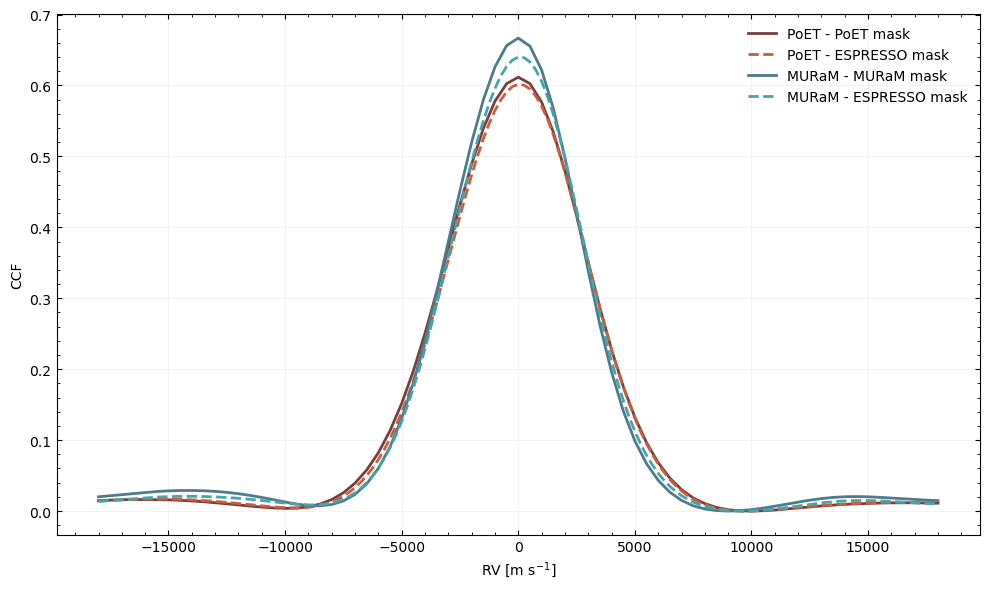

In [48]:
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(rv,ccf_p_own,lw=2,label='PoET - PoET mask', color="#773f3f")
ax.plot(rv,ccf_p_espresso,lw=2,ls='--',label='PoET - ESPRESSO mask', color="#cf5d3a")

ax.plot(rv,ccf_m_own,lw=2,label='MURaM - MURaM mask', color="#4f7b8a")
ax.plot(rv,ccf_m_espresso,lw=2,ls='--',label='MURaM - ESPRESSO mask', color="#45a5aa")

ax.set_xlabel(r'RV [m s$^{-1}$]')
ax.set_ylabel('CCF')

ax.tick_params(which='both',direction='in',top=True,right=True)
ax.minorticks_on()
ax.legend(frameon=False)
ax.grid(alpha=0.15,linewidth=0.7)

plt.tight_layout()
plt.savefig(path_figs+'Fig_CCF_new_mask_vs_ESPRESSO.png', bbox_inches='tight', dpi=1000)

plt.show()

In [49]:
rvs_p_own, _, fwhm_p_own, bis_p_own, x_bis_p_own, y_bis_p_own = compute_ccf_params(rv,[ccf_p_own],False)
rvs_p_espresso, _, fwhm_p_espresso, bis_p_espresso, x_bis_p_espresso, y_bis_p_espresso = compute_ccf_params(rv,[ccf_p_espresso],False)

rvs_m_own, _, fwhm_m_own, bis_m_own, x_bis_m_own, y_bis_m_own = compute_ccf_params(rv,[ccf_m_own],False)
rvs_m_espresso, _, fwhm_m_espresso, bis_m_espresso, x_bis_m_espresso, y_bis_m_espresso = compute_ccf_params(rv,[ccf_m_espresso],False)

In [50]:
print('PoET - PoET mask:       ',rvs_p_own,fwhm_p_own,bis_p_own)
print('PoET - ESPRESSO mask:   ',rvs_p_espresso,fwhm_p_espresso,bis_p_espresso)
print('MURaM - MURaM mask:     ',rvs_m_own,fwhm_m_own,bis_m_own)
print('MURaM - ESPRESSO mask:  ',rvs_m_espresso,fwhm_m_espresso,bis_m_espresso)

PoET - PoET mask:        [-78.53717873] [6904.83710931] [-69.79548792]
PoET - ESPRESSO mask:    [-14.67409475] [6834.85887348] [-61.31549437]
MURaM - MURaM mask:      [-124.95742656] [6347.86031926] [-101.519213]
MURaM - ESPRESSO mask:   [-25.87634335] [6452.83820212] [-93.12986009]


In [51]:
print('PoET:')
print('ΔRV   =',np.asarray(rvs_p_own)-np.asarray(rvs_p_espresso),'m/s')
print('ΔFWHM =',np.asarray(fwhm_p_own)-np.asarray(fwhm_p_espresso),'m/s')
print('ΔBIS  =',np.asarray(bis_p_own)-np.asarray(bis_p_espresso),'m/s')

print('\nMURaM:')
print('ΔRV   =',np.asarray(rvs_m_own)-np.asarray(rvs_m_espresso),'m/s')
print('ΔFWHM =',np.asarray(fwhm_m_own)-np.asarray(fwhm_m_espresso),'m/s')
print('ΔBIS  =',np.asarray(bis_m_own)-np.asarray(bis_m_espresso),'m/s')

PoET:
ΔRV   = [-63.86308398] m/s
ΔFWHM = [69.97823583] m/s
ΔBIS  = [-8.47999355] m/s

MURaM:
ΔRV   = [-99.08108321] m/s
ΔFWHM = [-104.97788286] m/s
ΔBIS  = [-8.38935291] m/s


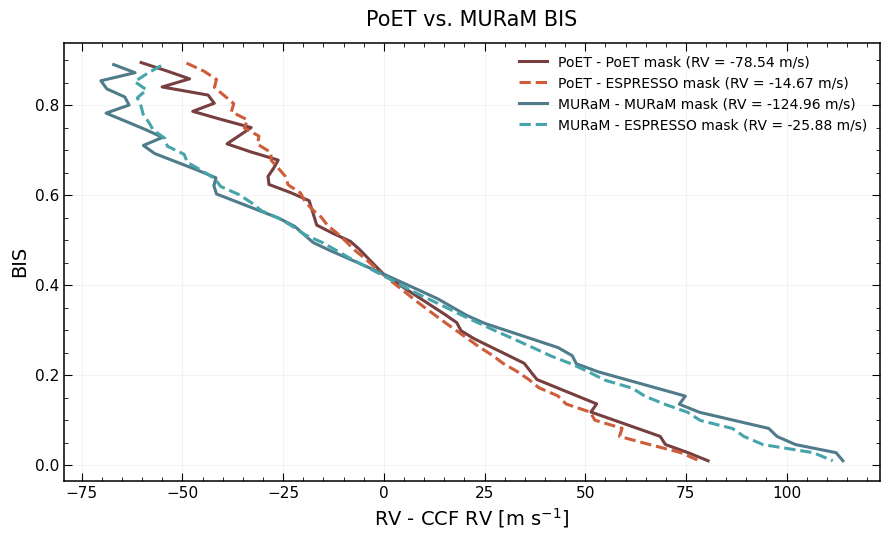

In [52]:
fig, ax = plt.subplots(figsize=(9,5.5))

ax.plot(x_bis_p_own[0]-rvs_p_own[0],1-y_bis_p_own[0],lw=2.2,label=fr'PoET - PoET mask (RV = {rvs_p_own[0]:.2f} m/s)',zorder=3, color="#773f3f")
ax.plot(x_bis_p_espresso[0]-rvs_p_espresso[0],1-y_bis_p_espresso[0],lw=2.2,ls='--',label=fr'PoET - ESPRESSO mask (RV = {rvs_p_espresso[0]:.2f} m/s)',zorder=3, color="#cf5d3a")

ax.plot(x_bis_m_own[0]-rvs_m_own[0],1-y_bis_m_own[0],lw=2.2,label=fr'MURaM - MURaM mask (RV = {rvs_m_own[0]:.2f} m/s)',zorder=3, color="#4f7b8a")
ax.plot(x_bis_m_espresso[0]-rvs_m_espresso[0],1-y_bis_m_espresso[0],lw=2.2,ls='--',label=fr'MURaM - ESPRESSO mask (RV = {rvs_m_espresso[0]:.2f} m/s)',zorder=3, color="#45a5aa")

ax.set_xlabel(r'RV - CCF RV [m s$^{-1}$]',fontsize=14)
ax.set_ylabel('BIS',fontsize=14)
ax.set_title('PoET vs. MURaM BIS',fontsize=15,pad=12)

ax.legend(frameon=False,fontsize=10)

ax.tick_params(axis='both',which='major',labelsize=11,direction='in',top=True,right=True,length=6)
ax.tick_params(axis='both',which='minor',direction='in',top=True,right=True,length=3)
ax.minorticks_on()

ax.grid(alpha=0.15,linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig(path_figs+'Fig_BIS_new_mask_vs_ESPRESSO.png', bbox_inches='tight', dpi=1000)
plt.show()

In [55]:
wvm_e_full = np.asarray(df_mask['wave'],dtype=np.float64)
fm_e_full = np.asarray(df_mask['weight'],dtype=np.float64)
fm_e_full = fm_e_full/np.sum(fm_e_full)

ccf_p_espresso_full = nbspectra.cross_correlation_mask(np.asarray(rv,dtype=np.float64),np.asarray(wave_p,dtype=np.float64),np.asarray(flux_p,dtype=np.float64),wvm_e_full,fm_e_full, phoenix_resolution=False, ccf_norm=False)
ccf_m_espresso_full = nbspectra.cross_correlation_mask(np.asarray(rv,dtype=np.float64),np.asarray(wave,dtype=np.float64),np.asarray(flux,dtype=np.float64),wvm_e_full,fm_e_full, phoenix_resolution=False, ccf_norm=False)

In [56]:
rvs_p_espresso_full, _, fwhm_p_espresso_full, bis_p_espresso_full, x_bis_p_espresso_full, y_bis_p_espresso_full = compute_ccf_params(rv,[ccf_p_espresso_full],False)
rvs_m_espresso_full, _, fwhm_m_espresso_full, bis_m_espresso_full, x_bis_m_espresso_full, y_bis_m_espresso_full = compute_ccf_params(rv,[ccf_m_espresso_full],False)

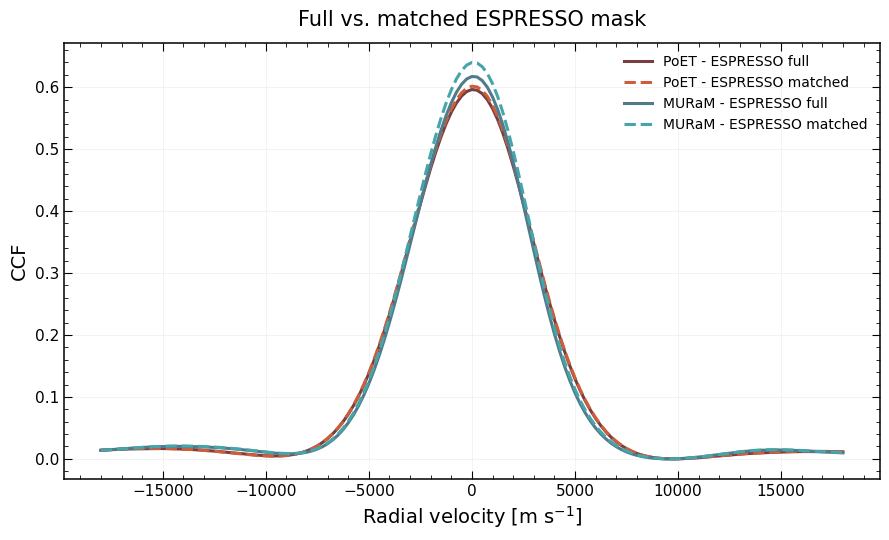

In [57]:
fig, ax = plt.subplots(figsize=(9,5.5))

ax.plot(rv,ccf_p_espresso_full,lw=2.2,label='PoET - ESPRESSO full',zorder=3,color="#773f3f")
ax.plot(rv,ccf_p_espresso,lw=2.2,ls='--',label='PoET - ESPRESSO matched',zorder=3,color="#cf5d3a")

ax.plot(rv,ccf_m_espresso_full,lw=2.2,label='MURaM - ESPRESSO full',zorder=3,color="#4f7b8a")
ax.plot(rv,ccf_m_espresso,lw=2.2,ls='--',label='MURaM - ESPRESSO matched',zorder=3,color="#45a5aa")

ax.set_xlabel(r'Radial velocity [m s$^{-1}$]',fontsize=14)
ax.set_ylabel('CCF',fontsize=14)
ax.set_title('Full vs. matched ESPRESSO mask',fontsize=15,pad=12)

ax.legend(frameon=False,fontsize=10)

ax.tick_params(axis='both',which='major',labelsize=11,direction='in',top=True,right=True,length=6)
ax.tick_params(axis='both',which='minor',direction='in',top=True,right=True,length=3)
ax.minorticks_on()

ax.grid(alpha=0.15,linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig(path_figs+'Fig_CCF_new_vs_old_ESPRESSO.png', bbox_inches='tight', dpi=1000)

plt.show()

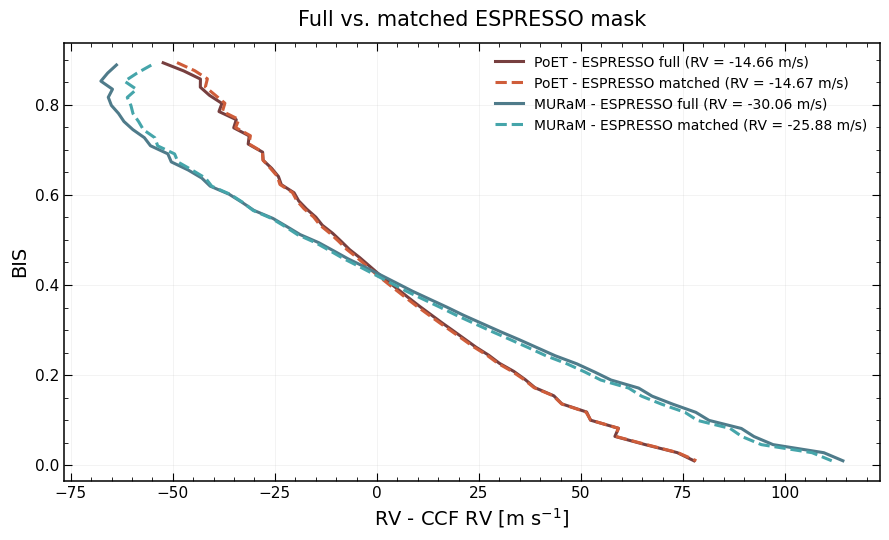

In [58]:
fig, ax = plt.subplots(figsize=(9,5.5))

ax.plot(x_bis_p_espresso_full[0]-rvs_p_espresso_full[0],1-y_bis_p_espresso_full[0],lw=2.2,label=fr'PoET - ESPRESSO full (RV = {rvs_p_espresso_full[0]:.2f} m/s)',zorder=3,color="#773f3f")
ax.plot(x_bis_p_espresso[0]-rvs_p_espresso[0],1-y_bis_p_espresso[0],lw=2.2,ls='--',label=fr'PoET - ESPRESSO matched (RV = {rvs_p_espresso[0]:.2f} m/s)',zorder=3,color="#cf5d3a")

ax.plot(x_bis_m_espresso_full[0]-rvs_m_espresso_full[0],1-y_bis_m_espresso_full[0],lw=2.2,label=fr'MURaM - ESPRESSO full (RV = {rvs_m_espresso_full[0]:.2f} m/s)',zorder=3,color="#4f7b8a")
ax.plot(x_bis_m_espresso[0]-rvs_m_espresso[0],1-y_bis_m_espresso[0],lw=2.2,ls='--',label=fr'MURaM - ESPRESSO matched (RV = {rvs_m_espresso[0]:.2f} m/s)',zorder=3,color="#45a5aa")

ax.set_xlabel(r'RV - CCF RV [m s$^{-1}$]',fontsize=14)
ax.set_ylabel('BIS',fontsize=14)
ax.set_title('Full vs. matched ESPRESSO mask',fontsize=15,pad=12)

ax.legend(frameon=False,fontsize=10)

ax.tick_params(axis='both',which='major',labelsize=11,direction='in',top=True,right=True,length=6)
ax.tick_params(axis='both',which='minor',direction='in',top=True,right=True,length=3)
ax.minorticks_on()

ax.grid(alpha=0.15,linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig(path_figs+'Fig_BIS_new_vs_old_ESPRESSO.png', bbox_inches='tight', dpi=1000)

plt.show()

## Disc centre (µ = 1.0) and disc-integrated spectra computed with SunSim: MURaM and PoET

The same CCFs, with two other kinds of spectra, both from the 10 µ angles of these files:

* **MURaM**: `MPS-ATLAS spectra/av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy`;
* **PoET**: `poet/sunsim/av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid_cleaned.npy`, corrected for its velocity of 149.28 m/s.

The two kinds of spectra:

* **µ = 1.0**: the specific intensity at the disc centre;
* **disc-integrated (SunSim)**: `flux_grid` in spectroscopy mode, 20 rings, solar rotation (equatorial period 24.47 d, inclination 7.25°, solar differential rotation): the spectrum of every cell is Doppler shifted by its rotation velocity, and the disc-integrated spectrum is the sum of all the cells.

The files are in vacuum wavelengths: converted to air (VALD and the ESPRESSO mask are in air). The spectra are flattened with SNT as the disc-integrated MURaM spectrum in `masks.ipynb` (cut at 4200 Å, FWHM 0.1 Å below and 0.5 Å above).

**Masks.** The cross-match with the ESPRESSO mask is not redone: the lines are those of the ESPRESSO selection above (`matched`, 2996 lines).

* **ESPRESSO matched**: `wvm_e`, `fm_e` (above);
* **ESPRESSO full**: `wvm_e_full`, `fm_e_full` (above);
* **own mask** of every spectrum: the same lines, found in the new spectrum through their VALD line. The lines are detected and paired between PoET and MURaM as above, and every line of `matched` whose VALD line is a common line of the new spectra is kept, with the position of its minimum and its weight measured in the new spectrum.

In [51]:
# Spectra at the disc centre (mu = 1.0) and disc-integrated spectra (SunSim, solar rotation) of MURaM and PoET:
# in air, flattened
from SNT import normalize_spectra          # https://github.com/iastro-pt/Spectra-Normalization-Tool
import loguru
loguru.logger.disable('SNT')

file_spectra = {'PoET': '/Users/sophiestucki/Documents/poet/sunsim/av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid_cleaned.npy',
                'MURaM': ('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/Shared drives/Exoplanets-Group/'
                          'MPS-ATLAS spectra/av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy')}
rv_shift = {'PoET': 149.28181995, 'MURaM': 0.0}   # [m/s] velocity removed: wave * (1 - v/c) (as SUN_SPECTRUM_POET.csv)
c_light = 2.99792458e8                             # [m/s]

# disc-integrated spectra
N_rings_disc = 20                         # 20 rings: ~4 GB while the grid is built (10 rings: 1.3 GB, spectrum within 0.25 %)
rotation_period_sun = 24.47               # [days] at the equator
inclination_sun = np.deg2rad(7.25)        # [rad] (0 = equator-on)

# flattening (as the disc-integrated MURaM spectrum in masks.ipynb)
cut_wave = 4200.0      # [A] the blue and red parts are flattened separately
overlap = 5.0          # [A] each part is fitted up to this distance beyond the cut (SNT leaves NaN at the edges of a part)
fwhm_blue = 0.1        # FWHM for the blue part
fwhm_red = 0.5         # FWHM for the red part

cases = {'mu1': r'$\mu$ = 1.0', 'disc': 'disc-integrated, SunSim'}

def read_spectra(file):
    """Spectra {mu: {'wav', 'intensity'}} (vacuum), without the zeros at the edges of the cleaned files (same range for every mu)."""
    d = np.load(file, allow_pickle=True).item()
    spec = {float(mu): {'wav': np.asarray(v['wav'], dtype=np.float64), 'intensity': np.asarray(v['intensity'], dtype=np.float64)}
            for mu, v in d.items()}
    nz = np.where(np.all([s['intensity'] > 0 for s in spec.values()], axis=0))[0]
    return {mu: {'wav': s['wav'][nz[0]:nz[-1] + 1], 'intensity': s['intensity'][nz[0]:nz[-1] + 1]} for mu, s in spec.items()}

def disc_integrated(spec):
    """Disc-integrated spectrum: sum of all the cells, Doppler shifted by the rotation (wavelengths shortened at both ends)."""
    w = spec[1.0]['wav']
    g = flux_grid(N_rings_disc, spec, 'quiet', None, w[0], w[-1], rotation_period=rotation_period_sun, inclination=inclination_sun,
                  stellar_radius=1.0, stellar_rotation=True, mode='spectroscopy', differential_rotation=SOLAR_DIFFERENTIAL_ROTATION)
    g.built_grid()
    out = g.wv.copy(), g.grid.sum(axis=0)
    del g
    return out

def flatten(w, f):
    def continuum_part(mask, fwhm_part):
        return normalize_spectra(wavelengths=w[mask], spectra=f[mask], FWHM_override=fwhm_part, header={},
                                 output_path='', store_to_disk=False, fname='')[0]
    blue = w < cut_wave
    cont_blue = continuum_part(w < cut_wave + overlap, fwhm_blue)
    cont_red = continuum_part(w >= cut_wave - overlap, fwhm_red)
    cont = np.empty_like(f)
    cont[blue] = cont_blue[:np.sum(blue)]
    cont[~blue] = cont_red[-np.sum(~blue):]
    return f / cont

spec_new = {case: {} for case in cases}           # spec_new[case][name] = (wavelengths [A, air], flattened flux)
for name, file in file_spectra.items():
    spec = read_spectra(file)
    raw = {'mu1': (spec[1.0]['wav'], spec[1.0]['intensity']), 'disc': disc_integrated(spec)}
    del spec
    for case, (w_vac, f) in raw.items():
        w = vacuum2air(w_vac) * (1 - rv_shift[name] / c_light)
        fn = flatten(w, f)
        ok = np.isfinite(fn)                      # the continuum is NaN only for a few pixels at the two ends: removed
        spec_new[case][name] = (w[ok], fn[ok])
        print('%-5s %-25s %d pixels, %.2f-%.2f A' % (name, cases[case], ok.sum(), w[ok][0], w[ok][-1]))

PoET  $\mu$ = 1.0               440023 pixels, 3781.29-7876.83 A


PoET  disc-integrated, SunSim   440008 pixels, 3781.38-7876.83 A


MURaM $\mu$ = 1.0               499969 pixels, 3798.93-7997.51 A


MURaM disc-integrated, SunSim   499951 pixels, 3799.02-7997.48 A


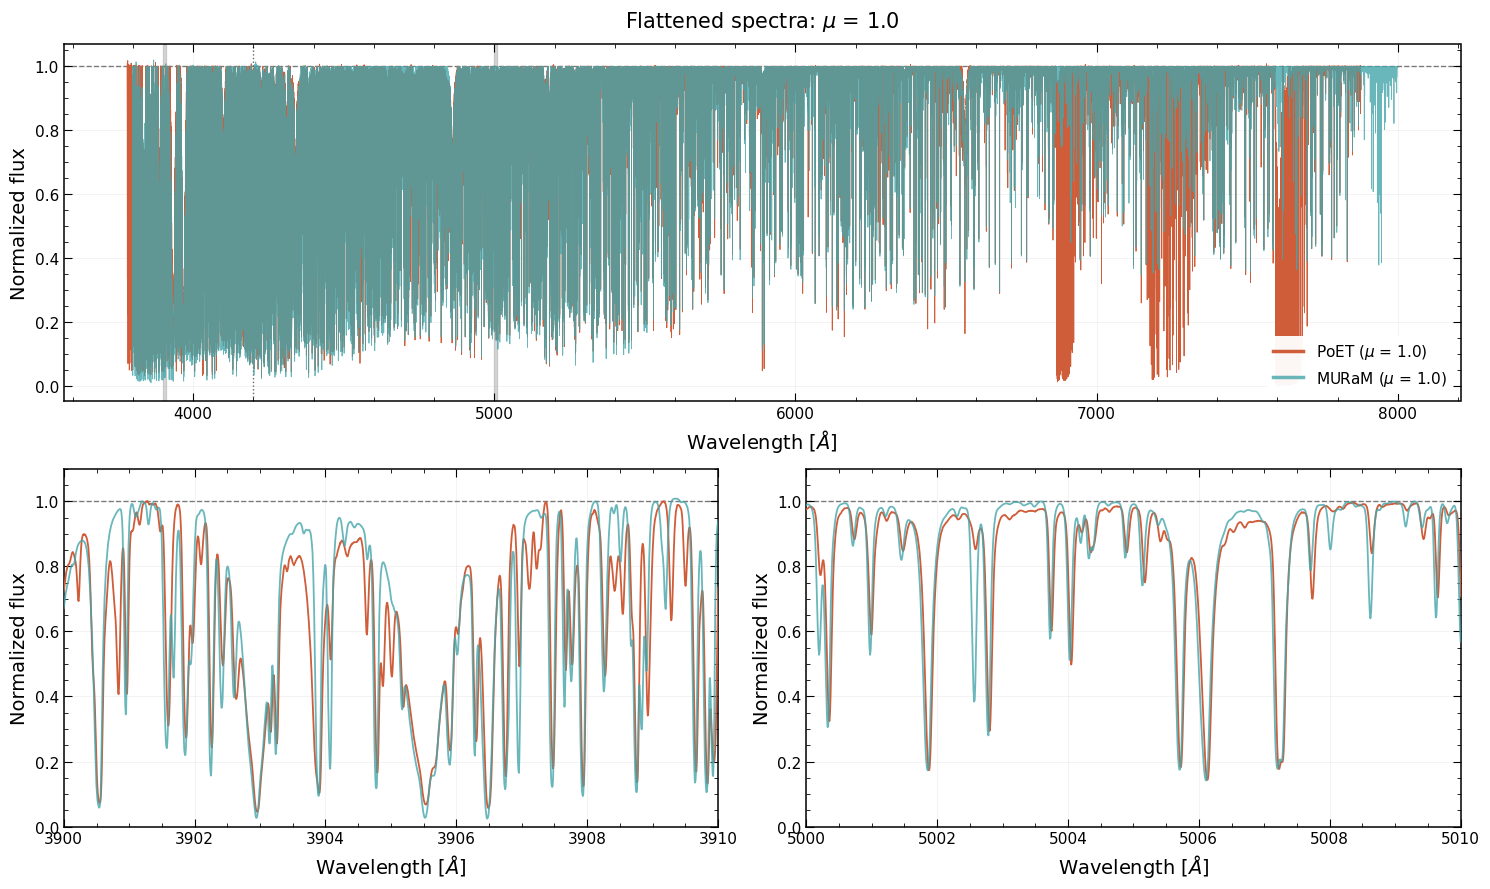

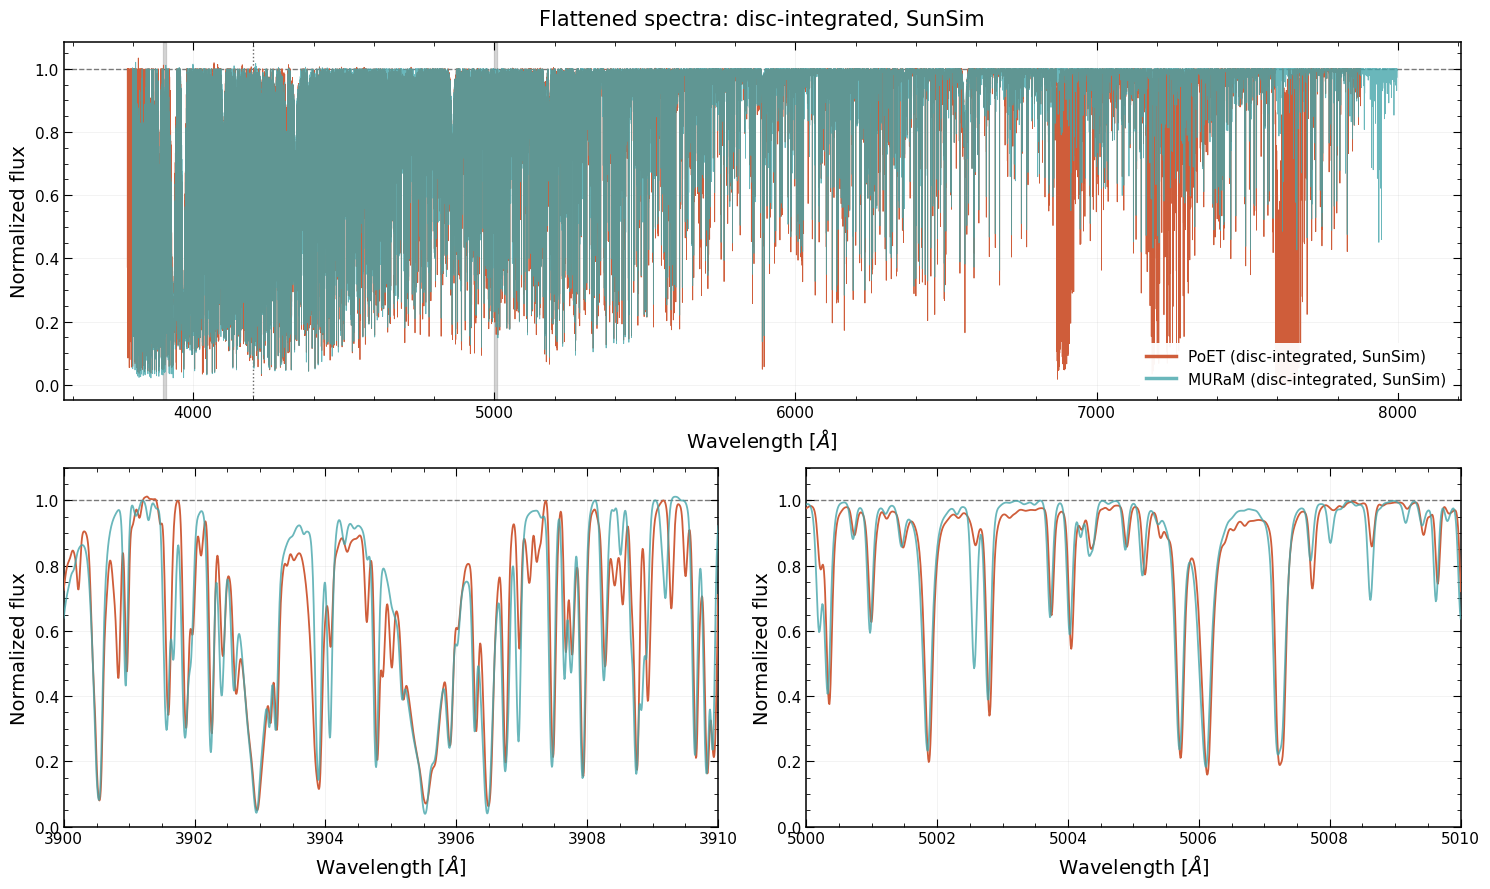

In [52]:
# Flattened spectra: whole range, and two zooms (blue, below the cut, and 5000-5010 A)
zooms = [(3900, 3910), (5000, 5010)]
colors = {'PoET': "#cf5d3a", 'MURaM': "#45a5aa"}

for case, case_label in cases.items():
    fig = plt.figure(figsize=(15, 9))
    gs = fig.add_gridspec(2, 2)
    ax0 = fig.add_subplot(gs[0, :])
    axz = [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
    for ax in [ax0] + axz:
        for name in ('PoET', 'MURaM'):
            w, f = spec_new[case][name]
            ax.plot(w, f, lw=0.6 if ax is ax0 else 1.3, color=colors[name], alpha=0.8 if name == 'MURaM' else 1,
                    label=f'{name} ({case_label})', zorder=3)
        ax.axhline(1, color='k', ls='--', lw=1, alpha=0.5)
        ax.set_xlabel(r'Wavelength [$\AA$]', fontsize=14)
        ax.set_ylabel('Normalized flux', fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
        ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
        ax.minorticks_on()
        ax.grid(alpha=0.15, linewidth=0.7)
        for spine in ax.spines.values():
            spine.set_linewidth(1.1)
    for ax, (lo, hi) in zip(axz, zooms):
        ax.set_xlim(lo, hi)
        ax.set_ylim(0, 1.1)
        ax0.axvspan(lo, hi, color='k', alpha=0.15, zorder=1)
    ax0.axvline(cut_wave, color='k', ls=':', lw=1, alpha=0.6)
    ax0.set_title(f'Flattened spectra: {case_label}', fontsize=15, pad=12)
    leg = ax0.legend(frameon=True, framealpha=0.95, edgecolor='none', fontsize=11, loc='lower right')
    for h in leg.legend_handles:
        h.set_linewidth(2.5)
    plt.tight_layout()
    plt.show()

In [53]:
# Lines of the new spectra, common PoET/MURaM lines and line weights (as above), and the own masks: the lines of the
# ESPRESSO selection above (`matched`, not redone), found in the new spectra through their VALD line
vald_matched = lines_p['vald_index'].values[matched['common_index'].astype(int).values]   # VALD line of every line of `matched`

lines_new, own_masks = {}, {}
for case, case_label in cases.items():
    (w_p, f_p), (w_m, f_m) = spec_new[case]['PoET'], spec_new[case]['MURaM']
    lp = find_spectral_lines(w_p, f_p, df_vald, tolerance=tolerance, prominence=prominence, distance_weight=0.5, depth_weight=0.5)
    lm = find_spectral_lines(w_m, f_m, df_vald, tolerance=tolerance, prominence=prominence, distance_weight=0.5, depth_weight=0.5)
    n_detected = (len(lp), len(lm))
    lp, lm = pair_common_lines(lp, lm)
    lp = compute_line_weights(w_p, f_p, lp, sigma=0)
    lm = compute_line_weights(w_m, f_m, lm, sigma=0)
    lines_new[case] = (lp, lm)

    # row of every VALD line in the common lines of the new spectra
    row = pd.Series(np.arange(len(lp)), index=lp['vald_index'].values)
    row = row[~row.index.duplicated()]
    found = np.isin(vald_matched, row.index)
    k = row.loc[vald_matched[found]].values
    m = pd.DataFrame({'espresso_index': matched['espresso_index'].values[found], 'wave_espresso': matched['wave_espresso'].values[found],
                      'wave_poet': lp['wave_min'].values[k], 'weight_poet': lp['weight'].values[k],
                      'wave_muram': lm['wave_min'].values[k], 'weight_muram': lm['weight'].values[k]})
    for col in ('poet', 'muram'):
        m['weight_%s_norm' % col] = m['weight_%s' % col] / m['weight_%s' % col].sum()
    own_masks[case] = m
    print('%-25s detected lines: PoET %d, MURaM %d; common lines: %d; lines of `matched` found: %d of %d'
          % (case_label, *n_detected, len(lp), found.sum(), len(matched)))

$\mu$ = 1.0               detected lines: PoET 9945, MURaM 8766; common lines: 6398; lines of `matched` found: 2457 of 2996


disc-integrated, SunSim   detected lines: PoET 8650, MURaM 7721; common lines: 5809; lines of `matched` found: 2442 of 2996


In [54]:
# CCFs (same velocity grid and normalisation as above): own masks, ESPRESSO matched (wvm_e, fm_e) and ESPRESSO full
def ccf_of(w, f, wm, fm):
    return nbspectra.cross_correlation_mask(np.asarray(rv, dtype=np.float64), np.asarray(w, dtype=np.float64), np.asarray(f, dtype=np.float64),
                                            np.asarray(wm, dtype=np.float64), np.asarray(fm, dtype=np.float64), phoenix_resolution=False, ccf_norm=False)

ccf_new, par_new = {}, {}         # [case, spectrum, mask]: CCF; (RV, contrast, FWHM, BIS, x_bis, y_bis) from compute_ccf_params
for case in cases:
    m = own_masks[case]
    for name in ('PoET', 'MURaM'):
        w, f = spec_new[case][name]
        masks_used = {'own': (m['wave_' + name.lower()], m['weight_%s_norm' % name.lower()]),
                      'ESPRESSO matched': (wvm_e, fm_e), 'ESPRESSO full': (wvm_e_full, fm_e_full)}
        for mask_name, (wm, fm) in masks_used.items():
            ccf_new[case, name, mask_name] = ccf_of(w, f, wm, fm)
            par_new[case, name, mask_name] = compute_ccf_params(rv, [ccf_new[case, name, mask_name]], False)

# table, with the disc-integrated spectra of the first part (CSV files) for comparison
rows = [{'spectra': 'disc-integrated (CSV, above)', 'spectrum': name, 'mask': mask_name, 'RV [m/s]': r[0], 'FWHM [m/s]': fw[0], 'BIS [m/s]': b[0]}
        for name, mask_name, r, fw, b in [('PoET', 'own', rvs_p_own, fwhm_p_own, bis_p_own),
                                          ('PoET', 'ESPRESSO matched', rvs_p_espresso, fwhm_p_espresso, bis_p_espresso),
                                          ('PoET', 'ESPRESSO full', rvs_p_espresso_full, fwhm_p_espresso_full, bis_p_espresso_full),
                                          ('MURaM', 'own', rvs_m_own, fwhm_m_own, bis_m_own),
                                          ('MURaM', 'ESPRESSO matched', rvs_m_espresso, fwhm_m_espresso, bis_m_espresso),
                                          ('MURaM', 'ESPRESSO full', rvs_m_espresso_full, fwhm_m_espresso_full, bis_m_espresso_full)]]
rows += [{'spectra': cases[case], 'spectrum': name, 'mask': mask_name, 'RV [m/s]': p[0][0], 'FWHM [m/s]': p[2][0], 'BIS [m/s]': p[3][0]}
         for (case, name, mask_name), p in par_new.items()]
pd.options.display.float_format = '{:.2f}'.format
pd.DataFrame(rows).set_index(['spectra', 'spectrum', 'mask'])

RV [m/s]  FWHM [m/s]  \
spectra                      spectrum mask                                     
disc-integrated (CSV, above) PoET     own                 -78.54     6904.84   
                                      ESPRESSO matched    -14.67     6834.86   
                                      ESPRESSO full       -14.66     6828.20   
                             MURaM    own                -124.96     6347.86   
                                      ESPRESSO matched    -25.88     6452.84   
                                      ESPRESSO full       -30.06     6446.45   
$\mu$ = 1.0                  PoET     own                -153.08     6003.57   
                                      ESPRESSO matched    208.21     6152.19   
                                      ESPRESSO full       208.61     6146.08   
                             MURaM    own                -266.40     5788.78   
                                      ESPRESSO matched   -961.97     6073.01   
                                      ESPRESSO full      -965.62     6063.22   
disc-integrated, SunSim      PoET     own                 -79.08     6574.34   
                                      ESPRESSO matched    203.47     6567.53   
                                      ESPRESSO full       203.69     6561.96   
                             MURaM    own                -124.16     6806.57   
                                      ESPRESSO matched   -982.11     6849.53   
                                      ESPRESSO full      -986.61     6837.72   

                                                        BIS [m/s]  
spectra                      spectrum mask                         
disc-integrated (CSV, above) PoET     own                  -69.80  
                                      ESPRESSO matched     -61.32  
                                      ESPRESSO full        -62.45  
                             MURaM    own                 -101.52  
                                      ESPRESSO matched     -93.13  
                                      ESPRESSO full        -98.63  
$\mu$ = 1.0                  PoET     own                 -121.62  
                                      ESPRESSO matched     -90.25  
                                      ESPRESSO full        -91.09  
                             MURaM    own                 -193.98  
                                      ESPRESSO matched    -134.17  
                                      ESPRESSO full       -140.33  
disc-integrated, SunSim      PoET     own                  -73.35  
                                      ESPRESSO matched     -61.37  
                                      ESPRESSO full        -62.59  
                             MURaM    own                 -103.06  
                                      ESPRESSO matched     -87.69  
                                      ESPRESSO full        -92.99

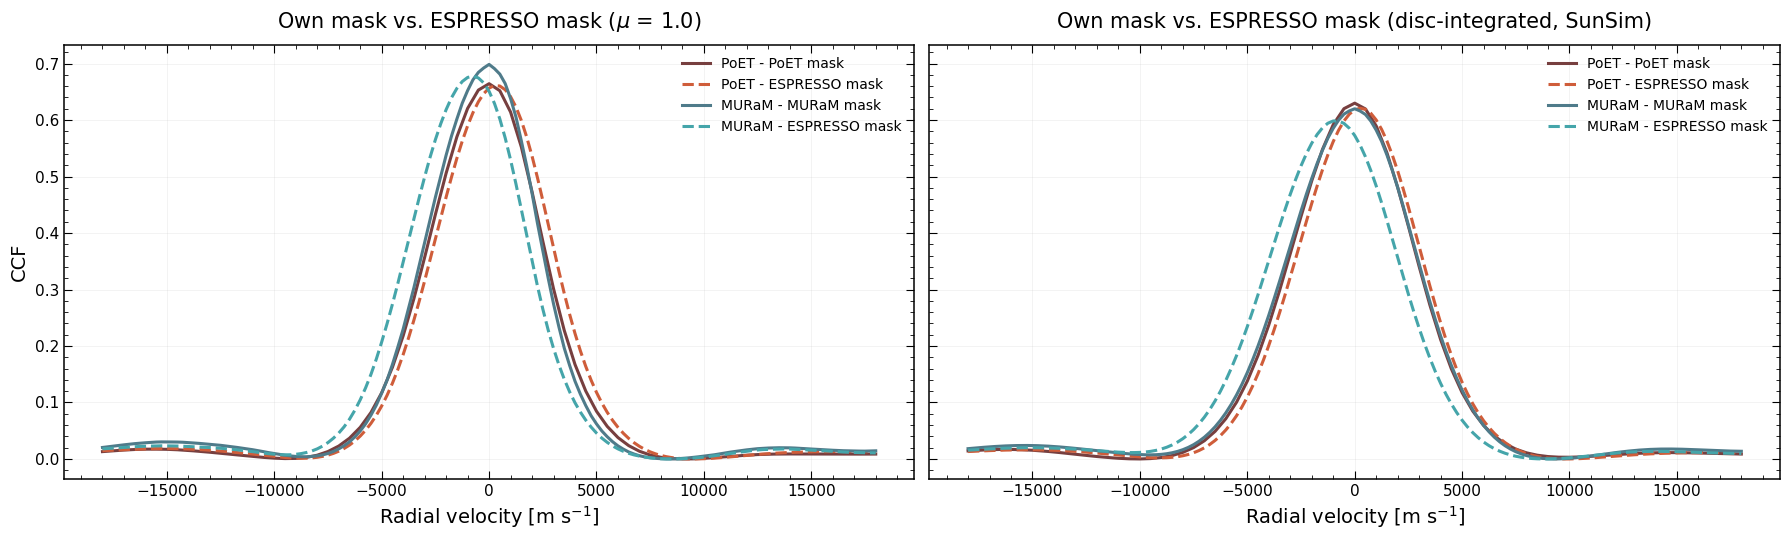

In [55]:
# Figures: one panel per kind of spectra (mu = 1.0, disc-integrated), the same curves and colours as the figures above
def plot_new(curves, what, title, figname):
    """curves: (spectrum, mask, label, colour, line style); what: 'ccf' or 'bis'."""
    fig, axes = plt.subplots(1, len(cases), figsize=(9 * len(cases), 5.5), sharey=True)
    for ax, (case, case_label) in zip(axes, cases.items()):
        for name, mask_name, label, color, ls in curves:
            if what == 'ccf':
                ax.plot(rv, ccf_new[case, name, mask_name], lw=2.2, ls=ls, label=label, zorder=3, color=color)
            else:
                r, _, _, _, xb, yb = par_new[case, name, mask_name]
                ax.plot(xb[0] - r[0], 1 - yb[0], lw=2.2, ls=ls, zorder=3, color=color, label=fr'{label} (RV = {r[0]:.2f} m/s)')
        ax.set_xlabel(r'Radial velocity [m s$^{-1}$]' if what == 'ccf' else r'RV - CCF RV [m s$^{-1}$]', fontsize=14)
        ax.set_title(f'{title} ({case_label})', fontsize=15, pad=12)
        ax.legend(frameon=False, fontsize=10)
        ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
        ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
        ax.minorticks_on()
        ax.grid(alpha=0.15, linewidth=0.7)
        for spine in ax.spines.values():
            spine.set_linewidth(1.1)
    axes[0].set_ylabel('CCF' if what == 'ccf' else 'BIS', fontsize=14)
    plt.tight_layout()
    plt.savefig(path_figs + figname, bbox_inches='tight', dpi=1000)
    plt.show()

own_vs_espresso = [('PoET', 'own', 'PoET - PoET mask', "#773f3f", '-'), ('PoET', 'ESPRESSO matched', 'PoET - ESPRESSO mask', "#cf5d3a", '--'),
                   ('MURaM', 'own', 'MURaM - MURaM mask', "#4f7b8a", '-'), ('MURaM', 'ESPRESSO matched', 'MURaM - ESPRESSO mask', "#45a5aa", '--')]
full_vs_matched = [('PoET', 'ESPRESSO full', 'PoET - ESPRESSO full', "#773f3f", '-'), ('PoET', 'ESPRESSO matched', 'PoET - ESPRESSO matched', "#cf5d3a", '--'),
                   ('MURaM', 'ESPRESSO full', 'MURaM - ESPRESSO full', "#4f7b8a", '-'), ('MURaM', 'ESPRESSO matched', 'MURaM - ESPRESSO matched', "#45a5aa", '--')]

plot_new(own_vs_espresso, 'ccf', 'Own mask vs. ESPRESSO mask', 'Fig_CCF_new_mask_vs_ESPRESSO_mu1_disc.png')

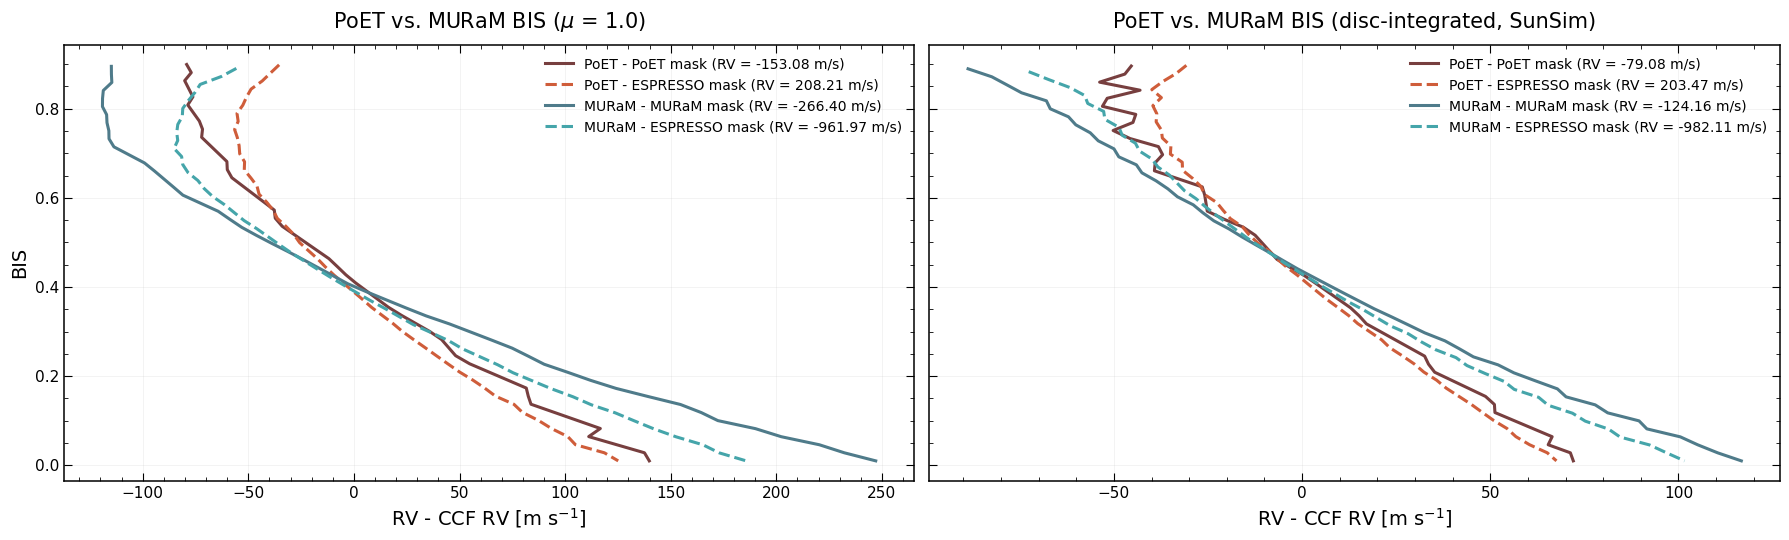

In [56]:
plot_new(own_vs_espresso, 'bis', 'PoET vs. MURaM BIS', 'Fig_BIS_new_mask_vs_ESPRESSO_mu1_disc.png')

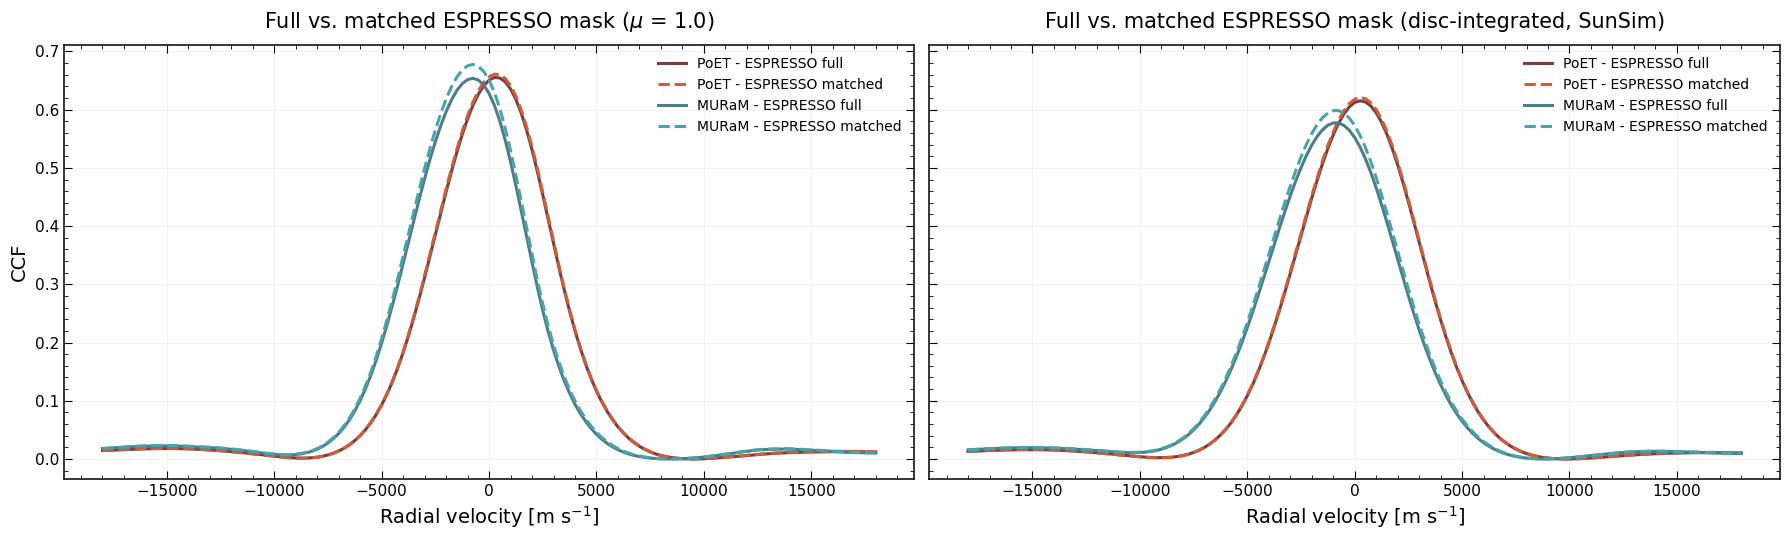

In [57]:
plot_new(full_vs_matched, 'ccf', 'Full vs. matched ESPRESSO mask', 'Fig_CCF_new_vs_old_ESPRESSO_mu1_disc.png')

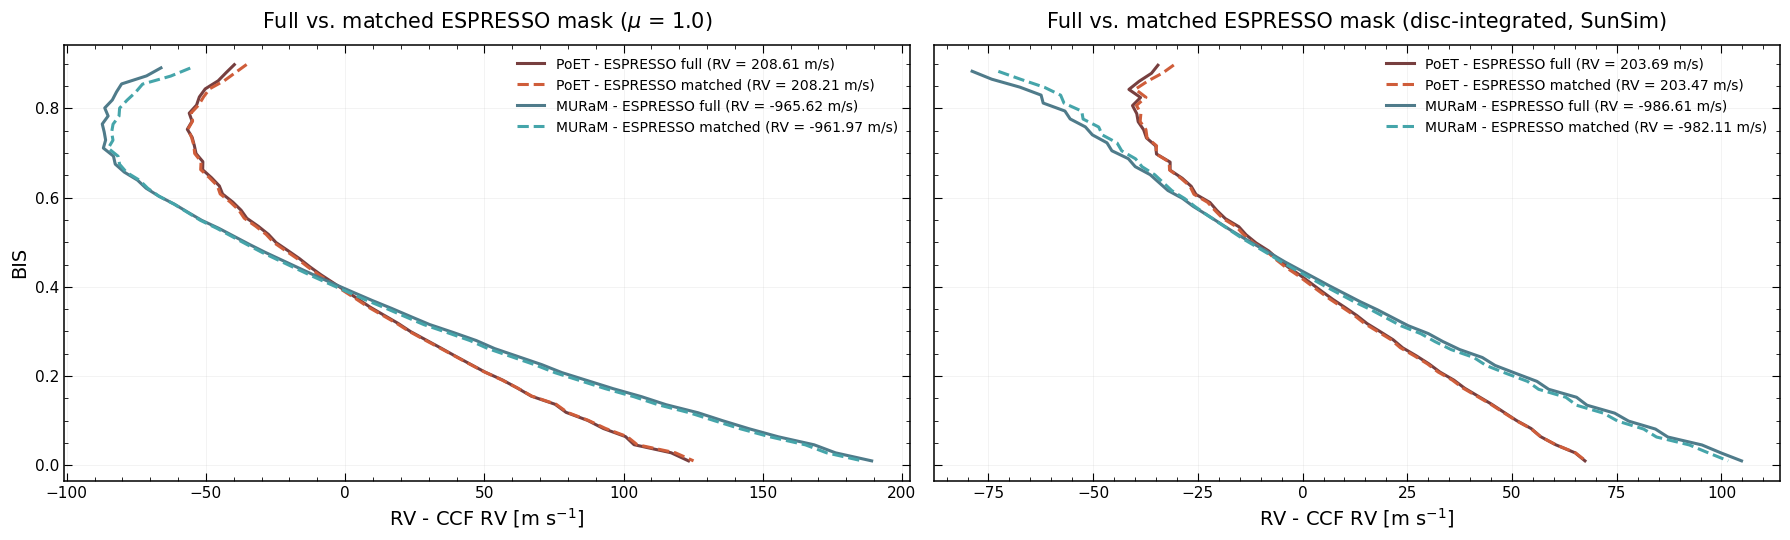

In [58]:
plot_new(full_vs_matched, 'bis', 'Full vs. matched ESPRESSO mask', 'Fig_BIS_new_vs_old_ESPRESSO_mu1_disc.png')

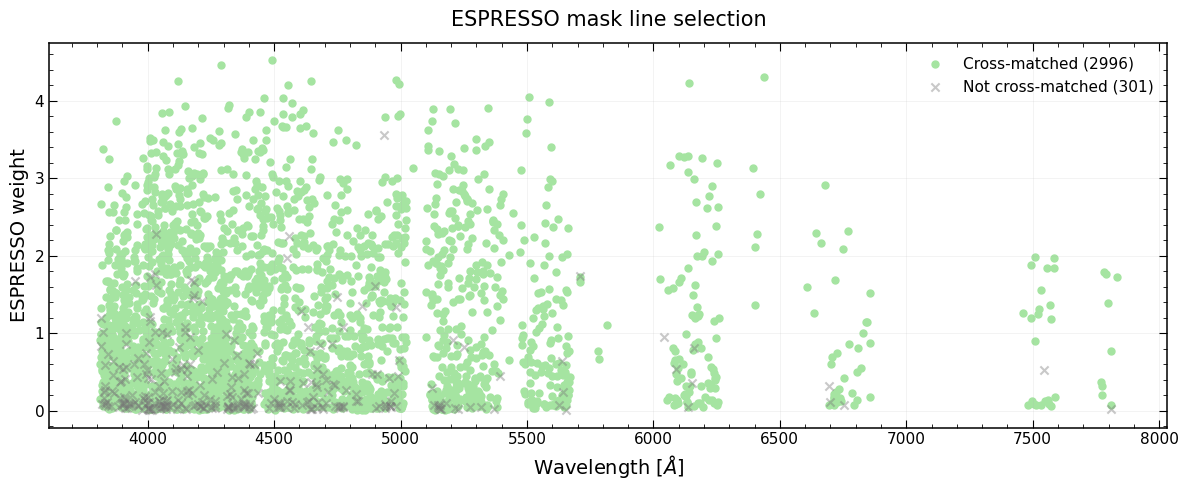

In [59]:
matched_idx = matched['espresso_index'].astype(int).values
is_matched = df_mask.index.isin(matched_idx)

fig, ax = plt.subplots(figsize=(12,5))

ax.scatter(df_mask.loc[is_matched,'wave'],df_mask.loc[is_matched,'weight'],s=25,alpha=1,label=f'Cross-matched ({is_matched.sum()})',color="#A5E4A1")
ax.scatter(df_mask.loc[~is_matched,'wave'],df_mask.loc[~is_matched,'weight'],s=35,marker='x',alpha=0.4,label=f'Not cross-matched ({(~is_matched).sum()})',color="#777777")

ax.set_xlabel(r'Wavelength [$\AA$]',fontsize=14)
ax.set_ylabel('ESPRESSO weight',fontsize=14)
ax.set_title('ESPRESSO mask line selection',fontsize=15,pad=12)

ax.legend(frameon=False,fontsize=11)

ax.tick_params(axis='both',which='major',labelsize=11,direction='in',top=True,right=True,length=6)
ax.tick_params(axis='both',which='minor',direction='in',top=True,right=True,length=3)
ax.minorticks_on()

ax.grid(alpha=0.15,linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig(path_figs+'Fig_ESPRESSO_line_selection_weight.png', bbox_inches='tight', dpi=1000)

plt.show()

301 unmatched ESPRESSO lines: 252 without a common line within 0.11 A, 49 removed by the 0.05 A selection


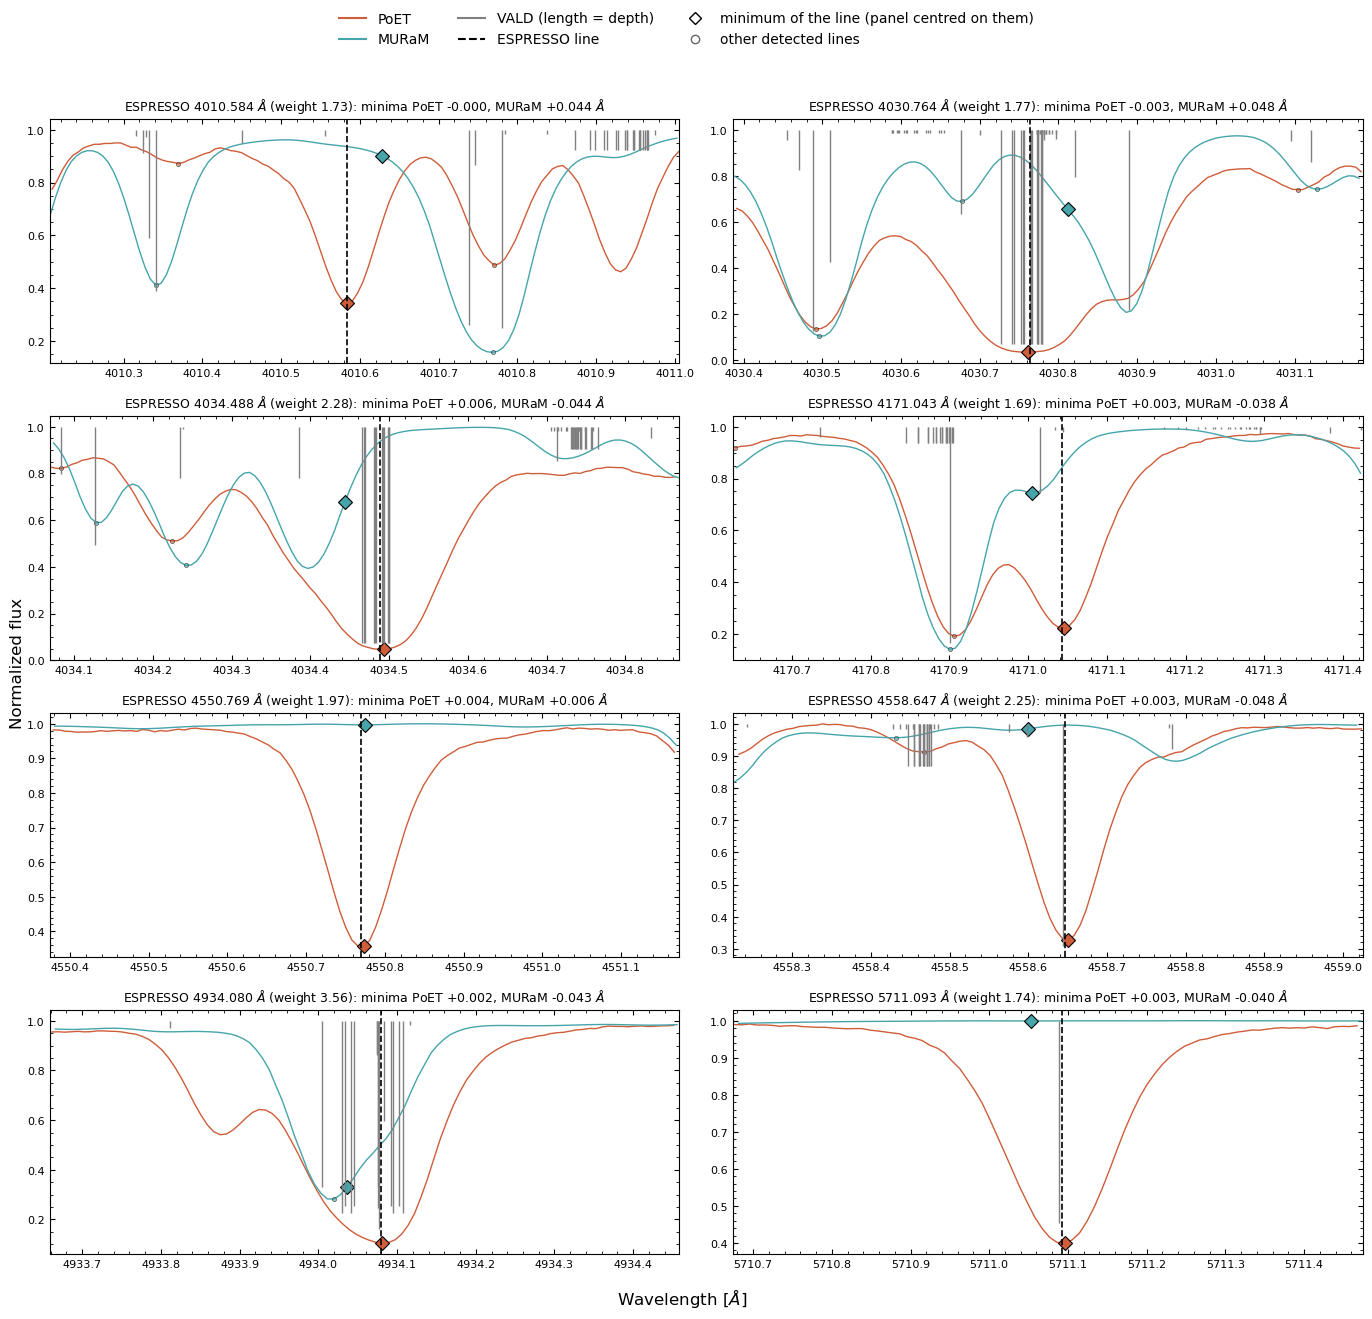

In [60]:
# Some ESPRESSO lines that are NOT in the final `matched` list: PoET and MURaM spectra around them, with the VALD lines
n_examples = 8               # number of lines shown
pick = 'weight'              # 'weight': the unmatched lines with the largest ESPRESSO weight; 'random': random ones
half_window = 0.4            # [A] half width of every panel
search = 0.05                # [A] the minimum of every spectrum is searched within +-search of the ESPRESSO line

unmatched = df_mask.loc[~df_mask.index.isin(matched['espresso_index'].astype(int).values)].copy()

# why is it not matched? distance to the closest common line (VALD wavelength), and offsets of the minima
common_vald = lines_p['vald_wave'].values
k_near = np.array([np.argmin(np.abs(common_vald - w)) for w in unmatched['wave']])
unmatched['d_common'] = np.abs(common_vald[k_near] - unmatched['wave'].values)
unmatched['dw_poet'] = lines_p['wave_min'].values[k_near] - unmatched['wave'].values
unmatched['dw_muram'] = lines['wave_min'].values[k_near] - unmatched['wave'].values

print('%d unmatched ESPRESSO lines: %d without a common line within %.2f A, %d removed by the 0.05 A selection'
      % (len(unmatched), np.sum(unmatched['d_common'] > tolerance_mask), tolerance_mask, np.sum(unmatched['d_common'] <= tolerance_mask)))

if pick == 'weight':
    shown = unmatched.sort_values('weight', ascending=False).head(n_examples)
else:
    shown = unmatched.sample(min(n_examples, len(unmatched)), random_state=1)
shown = shown.sort_values('wave')

ncol = 2
nrow = int(np.ceil(len(shown) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.3 * nrow), squeeze=False)
for ax, (j, row) in zip(axes.ravel(), shown.iterrows()):
    w_esp = row['wave']
    # minimum of every spectrum near the ESPRESSO line: the panel is centred on the mean of the two
    minima = {}
    for name, w, f in (('PoET', wave_p, flux_p), ('MURaM', wave, flux)):
        near = np.where((w > w_esp - search) & (w < w_esp + search))[0]
        i_min = near[np.argmin(f[near])]
        minima[name] = (w[i_min], f[i_min])
    w0 = np.mean([v[0] for v in minima.values()])
    lo, hi = w0 - half_window, w0 + half_window
    for name, w, f, tab, color in (('PoET', wave_p, flux_p, lines_p, '#cf5d3a'), ('MURaM', wave, flux, lines, '#45a5aa')):
        m = (w > lo) & (w < hi)
        ax.plot(w[m], f[m], '-', lw=1, color=color, label=name)
        mins = tab[(tab['wave_min'] > lo) & (tab['wave_min'] < hi)]          # other (matched) lines in the panel
        ax.plot(mins['wave_min'], mins['flux_min'], 'o', ms=3, color=color, mec='k', mew=0.5, alpha=0.6)
        ax.plot(*minima[name], 'D', ms=7, color=color, mec='k', mew=0.8)        # minimum of this line
    # VALD lines: sticks from the continuum, of length = VALD depth
    vm = (wave_vald > lo) & (wave_vald < hi)
    ax.vlines(wave_vald[vm], 1.0, 1.0 - depth_vald[vm], color='grey', lw=1)
    ax.axvline(w_esp, color='k', lw=1.2, ls='--')
    ax.set_xlim(lo, hi)
    ax.set_title('ESPRESSO %.3f $\\AA$ (weight %.2f): minima PoET %+.3f, MURaM %+.3f $\\AA$'
                 % (w_esp, row['weight'], minima['PoET'][0] - w_esp, minima['MURaM'][0] - w_esp), fontsize=9)
    ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=8)
    ax.ticklabel_format(axis='x', useOffset=False)           # real wavelengths on the axis
    ax.minorticks_on()
for ax in axes.ravel()[len(shown):]:
    ax.set_axis_off()
handles = [plt.Line2D([], [], color='#cf5d3a', label='PoET'), plt.Line2D([], [], color='#45a5aa', label='MURaM'),
           plt.Line2D([], [], color='grey', label='VALD (length = depth)'), plt.Line2D([], [], color='k', ls='--', label='ESPRESSO line'),
           plt.Line2D([], [], marker='D', ls='', color='w', mec='k', label='minimum of the line (panel centred on them)'),
           plt.Line2D([], [], marker='o', ls='', color='w', mec='k', alpha=0.6, label='other detected lines')]
fig.legend(handles=handles, loc='upper center', ncol=3, frameon=False, fontsize=10)
fig.supxlabel(r'Wavelength [$\AA$]')
fig.supylabel('Normalized flux')
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


In [ ]:
unmatched[np.abs(unmatched['wave'] - 4121.3) < 0.1]

,wave,cont,weight,d_common,dw_poet,dw_muram
857,4121.322366,2.062452,4.253706,0.479874,0.485877,0.488125


In [ ]:
lines_p_raw[np.abs(lines_p_raw['wave_min'] - 4121.3) < 0.1]

,wave_min,flux_min,i_left,wave_left_max,flux_left_max,i_right,wave_right_max,flux_right_max,depth,vald_index,vald_wave,vald_depth,delta_vald,vald_score,n_vald_candidates,candidates
2051,4121.320195,0.121672,53253,4121.16898,0.940517,53310,4121.560775,0.979963,0.838568,20548.0,4121.32003,0.897,0.000165,0.035051,22,"[20545, 20546, 20547, 20548, 20549, 20550, 205..."


In [ ]:
lines_raw[np.abs(lines_p_raw['wave_min'] - 4121.3) < 0.1]


/var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/ipykernel_57861/1915216318.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  lines_raw[np.abs(lines_p_raw['wave_min'] - 4121.3) < 0.1]


,wave_min,flux_min,i_left,wave_left_max,flux_left_max,i_right,wave_right_max,flux_right_max,depth,vald_index,vald_wave,vald_depth,delta_vald,vald_score,n_vald_candidates,candidates
2051,4279.71837,0.22963,71430,4279.589896,0.906684,71460,4279.804022,0.658674,0.55305,26634.0,4279.702,0.279,0.01637,0.285988,5,"[26632, 26633, 26634, 26635, 26636]"
